# SC4002 Group Assignment — Joint intent classification and slot filling on MASSIVE en-US

| Section | Contents |
|---|---|
| 1 | Setup |
| 2 | Load and verify the dataset (official splits) |
| 3 | Preprocessing (inputs and labels) |
| 4 | Shared evaluation: the official MASSIVE metrics (MASSIVE's own code, copied into this notebook), used for every experiment |
| 5 | **Stage 1** — baseline joint Transformer (GloVe input, BIO-constrained decoding) |
| 6 | **Stage 2** — AI-enhanced system: architecture, parameter count |
| 7 | Stage 2 — training and checkpoint selection (dev only) |
| 8 | Stage 2 — final evaluation of the frozen checkpoint (validation + single test run) |
| 9 | Results table |
| 10 | Stage 2 — error analysis on the test predictions |

Data use: the **train** split fits every parameter and vocabulary; the **dev** split selects epochs and the ensemble
vote threshold; the **test** split is scored exactly once, in Section 8, after everything is frozen.
Only `utt` is ever used as model input.

## 1. Setup

In [1]:
import os, re, json, time, math, random, copy, zlib, platform
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")   # needed for deterministic cuBLAS
from collections import Counter
from math import sqrt

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

import sklearn.metrics as sklm                # used by MASSIVE's eval_preds (Section 4)
from seqeval.metrics import f1_score          # used by MASSIVE's eval_preds (Section 4)

ROOT = os.path.abspath(".")
MASSIVE_PATH = os.path.join(ROOT, "1.0", "data", "en-US.jsonl")
GLOVE_PATH = os.path.join(ROOT, "embeddings", "glove.6B.300d.txt")        # word vectors (allowed pretrained input)
FASTTEXT_PATH = os.path.join(ROOT, "embeddings", "crawl-300d-2M.vec")
CKPT_DIR = os.path.join(ROOT, "checkpoints", "stage2")
LOG_DIR = os.path.join(ROOT, "logs", "stage2")
for d in (CKPT_DIR, LOG_DIR):
    os.makedirs(d, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 20)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# Deterministic kernels so that a rerun on the same GPU / software stack gives identical numbers
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)


print(f"python {platform.python_version()} | torch {torch.__version__} | device {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else ""))

python 3.12.3 | torch 2.6.0+cu124 | device cuda (NVIDIA RTX 6000 Ada Generation)


## 2. Load and verify the dataset

`1.0/data/en-US.jsonl` from the official MASSIVE 1.0 archive, partitioned by its own `partition` field.
`annot_utt` is parsed into word-level BIO tags and the gold set of `(slot type, span text)` pairs; the parse is
checked to reproduce `utt` word for word.

In [2]:
SLOT_RE = re.compile(r"\[\s*([^\[\]:]+?)\s*:\s*([^\[\]]*?)\s*\]")


def parse_annot(annot_utt):
    # 'wake me up at [time : five am]' -> tokens, BIO tags, gold set of (slot_type, span_text)
    tokens, tags, spans, pos = [], [], set(), 0
    for m in SLOT_RE.finditer(annot_utt):
        outside = annot_utt[pos:m.start()].split()
        tokens += outside
        tags += ["O"] * len(outside)
        slot_type, words = m.group(1).strip(), m.group(2).split()
        tokens += words
        tags += [f"B-{slot_type}"] + [f"I-{slot_type}"] * (len(words) - 1)
        spans.add((slot_type, " ".join(words)))
        pos = m.end()
    outside = annot_utt[pos:].split()
    tokens += outside
    tags += ["O"] * len(outside)
    return tokens, tags, spans


# MASSIVE gold slot labels: the loop below is MASSIVE's own, from scripts/create_hf_dataset.py
# (https://github.com/alexa/massive/blob/f966f21846043aabef9b0f974fa7970027f43738/scripts/create_hf_dataset.py,
# Apache-2.0, Copyright Amazon.com, Inc. or its affiliates), wrapped as a function.
def annot_to_slot_labels(annot_utt):
    """Gold per-word slot labels ('Other' outside a slot), exactly as MASSIVE's create_hf_dataset.py builds them."""
    labels = []
    label = 'Other'
    split_annot_utt = annot_utt.split()
    idx = 0
    while idx < len(split_annot_utt):
        if split_annot_utt[idx].startswith('['):
            label = split_annot_utt[idx].lstrip('[')
            idx += 2
        elif split_annot_utt[idx].endswith(']'):
            labels.append(label)
            label = 'Other'
            idx += 1
        else:
            labels.append(label)
            idx += 1
    return labels


def bio_to_slot_labels(tags):
    """One BIO tag per word -> MASSIVE's per-word slot labels ('O' -> 'Other', 'B-x' / 'I-x' -> 'x')."""
    return ['Other' if t == 'O' else t[2:] for t in tags]


def to_example(r):
    tokens, tags, spans = parse_annot(r["annot_utt"])
    assert tokens == r["utt"].split(), f"annot_utt and utt disagree for id {r['id']}"
    slot_labels = annot_to_slot_labels(r["annot_utt"])               # MASSIVE's own gold labels
    assert slot_labels == bio_to_slot_labels(tags), f"gold slot labels disagree for id {r['id']}"
    return {"id": r["id"], "utt": r["utt"], "annot_utt": r["annot_utt"], "slot_labels": slot_labels, "tokens": tokens, "tags": tags, "gold_spans": spans,
            "intent": r["intent"], "scenario": r["intent"].split("_", 1)[0]}


with open(MASSIVE_PATH, encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]
raw = {n: [r for r in records if r["partition"] == n] for n in ("train", "dev", "test")}
for name, label in (("train", "training"), ("dev", "validation"), ("test", "test")):
    print(f"{label:<10} ({name}): {len(raw[name]):,} examples")
assert len(records) == 16_521
assert (len(raw["train"]), len(raw["dev"]), len(raw["test"])) == (11_514, 2_033, 2_974)
data = {n: [to_example(r) for r in raw[n]] for n in raw}
ex = data["train"][0]
print("\nexample:", ex["utt"], "|", ex["intent"], "|", sorted(ex["gold_spans"]))

training   (train): 11,514 examples
validation (dev): 2,033 examples
test       (test): 2,974 examples



example: wake me up at nine am on friday | alarm_set | [('date', 'friday'), ('time', 'nine am')]


## 3. Preprocessing

Everything here is fitted on the **train split only**.

* **Labels** — 60 intents, 18 scenarios (the prefix of the intent name), 55 slot types → 111 BIO tags.
* **Units** — each whitespace token is split at English clitics (`what's` → `what` `'s`; `p.` → `p`), so word vectors
  are found for more of the input. Every token keeps the index of its first unit, so tags stay word-level and spans
  are always whole words of `utt`.
* **Per-unit inputs** — (a) a frozen 600-d vector = GloVe-6B-300d ⊕ fastText crawl-300d (rows: all train units plus
  the 2,000 most frequent GloVe words), (b) a trainable 100-d unit embedding with frequency-based word dropout
  (rare words are replaced by `<unk>` more often during training), (c) a character CNN, (d) hashed character 3–5-gram
  embeddings. Words never seen in train still get (a), (c), (d).

In [3]:
PAD, UNK = "<pad>", "<unk>"
MAX_SPAN = 10                    # longest slot span (words) the span head scores; longest train span is 10


class Vocab:
    def __init__(self, items, specials=(PAD, UNK)):
        self.itos = list(specials) + [x for x in items if x not in specials]
        self.stoi = {x: i for i, x in enumerate(self.itos)}

    def __len__(self):
        return len(self.itos)

    def get(self, x):
        return self.stoi.get(x, self.stoi.get(UNK, 0))


class Labels:
    # Intent / scenario / BIO tag inventories, fitted on train only.
    def __init__(self, train):
        self.intents = Vocab(sorted({e["intent"] for e in train}), specials=())
        self.scenarios = Vocab(sorted({e["scenario"] for e in train}), specials=())
        self.slot_types = sorted({t[2:] for e in train for t in e["tags"] if t != "O"})
        self.tags = Vocab(["O"] + [f"{p}-{s}" for s in self.slot_types for p in ("B", "I")], specials=())
        self.i2s = torch.tensor([self.scenarios.stoi[i.split("_", 1)[0]] for i in self.intents.itos])
        self.tag_type = torch.tensor([0] + [self.slot_types.index(t[2:]) + 1 for t in self.tags.itos[1:]])
        self.tag_is_b = torch.tensor([t.startswith("B-") for t in self.tags.itos])


labels = Labels(data["train"])
print(f"{len(labels.intents)} intents | {len(labels.scenarios)} scenarios | {len(labels.slot_types)} slot types | "
      f"{len(labels.tags)} BIO tags")
assert len(labels.intents) == 60 and len(labels.slot_types) == 55
assert max(len(s.split()) for e in data["train"] for _, s in e["gold_spans"]) <= MAX_SPAN

60 intents | 18 scenarios | 55 slot types | 111 BIO tags


In [4]:
CLITIC_RE = re.compile(r"^(.+?)(n't|'s|'re|'ve|'ll|'d|'m)$")


def clitic_units(token):
    if re.fullmatch(r"[a-z]\.", token):
        return [token[0]]
    m = CLITIC_RE.match(token)
    return [m.group(1), m.group(2)] if m else [token]


def split_units(tokens):
    # units for the encoder, index of each token's first unit, token index of every unit
    units, first, owner = [], [], []
    for ti, t in enumerate(tokens):
        first.append(len(units))
        us = clitic_units(t)
        units.extend(us)
        owner.extend([ti] * len(us))
    return units, first, owner


def char_ngrams(unit, buckets, n_min=3, n_max=5, max_grams=40):
    w = f"<{unit}>"
    grams = [w] + [w[i:i + n] for n in range(n_min, n_max + 1) for i in range(len(w) - n + 1)]
    return [1 + zlib.crc32(g.encode("utf-8")) % buckets for g in grams[:max_grams]]


def vector_keys(w):
    # lookup keys for a unit: itself, stripped of punctuation, and (for clitics / hyphenated words) its parts
    s = w.strip(".,!?;:\"()")
    keys = [w, s, s.replace(".", "")]
    m = re.fullmatch(r"(.+?)(n't|'s|'re|'ve|'ll|'d|'m|')", s)
    if m:
        keys.append(tuple(p for p in m.groups() if p))
    parts = [p for p in re.split(r"[-./&]", s) if p]
    if len(parts) > 1:
        keys.append(tuple(parts))
    return keys


def needed_keys(words):
    return {p for w in words for k in vector_keys(w) for p in (k if isinstance(k, tuple) else (k,))}


def read_vectors(path, wanted, top_k=0):
    vecs, top = {}, []
    with open(path, encoding="utf-8", errors="ignore") as f:
        for rank, line in enumerate(f):
            word, _, rest = line.rstrip("\n").partition(" ")
            if rank == 0 and rest.count(" ") < 5:          # fastText header line
                continue
            if word in wanted or len(top) < top_k:
                v = np.asarray(rest.split(" "), dtype=np.float32)
                if v.shape[0] != 300:
                    continue
                vecs[word] = v
                if len(top) < top_k:
                    top.append(word)
    return vecs, top


def lookup_vector(w, vecs):
    for k in vector_keys(w):
        if isinstance(k, tuple):
            if all(p in vecs for p in k):
                return np.mean([vecs[p] for p in k], axis=0)
        elif k in vecs:
            return vecs[k]
    return None


def build_features(train, labels, top_k=2000, ngram_buckets=5000, word_drop_alpha=0.25):
    counts = Counter(u for e in train for t in e["tokens"] for u in clitic_units(t))
    units = Vocab([w for w, _ in sorted(counts.items(), key=lambda kv: (-kv[1], kv[0]))])
    chars = Vocab(sorted({c for u in counts for c in u}))
    glove, glove_top = read_vectors(GLOVE_PATH, needed_keys(set(counts)), top_k=top_k)
    fasttext, _ = read_vectors(FASTTEXT_PATH, needed_keys(set(counts)) | set(glove_top))
    frozen_words = Vocab(units.itos[2:] + [w for w in glove_top if w not in units.stoi])
    table = np.zeros((len(frozen_words), 600), dtype=np.float32)
    found = [0, 0]
    for j, vecs in enumerate((glove, fasttext)):
        for i, w in enumerate(frozen_words.itos[2:], start=2):
            v = lookup_vector(w, vecs)
            if v is not None:
                table[i, 300 * j:300 * (j + 1)] = v
                found[j] += i < len(units)
    drop_p = torch.zeros(len(units))
    for i, w in enumerate(units.itos[2:], start=2):
        drop_p[i] = word_drop_alpha / (word_drop_alpha + counts[w])
    n_units = len(units) - 2
    print(f"train units {n_units:,} | chars {len(chars)} | frozen table {tuple(table.shape)} | "
          f"GloVe coverage {100 * found[0] / n_units:.1f}% | fastText coverage {100 * found[1] / n_units:.1f}%")
    return {"units": units, "chars": chars, "frozen_words": frozen_words, "table": torch.tensor(table),
            "drop_p": drop_p, "ngram_buckets": ngram_buckets}


t0 = time.time()
feats = build_features(data["train"], labels)
print(f"features built in {time.time() - t0:.0f}s")

train units 5,151 | chars 34 | frozen table (5871, 600) | GloVe coverage 96.4% | fastText coverage 96.9%
features built in 5s


In [5]:
def encode(examples, feats, labels, max_chars=20):
    out = []
    for e in examples:
        units, first, owner = split_units(e["tokens"])
        out.append({"units": [feats["units"].get(u) for u in units],
                    "frozen": [feats["frozen_words"].get(u) for u in units],
                    "chars": [[feats["chars"].get(c) for c in u[:max_chars]] for u in units],
                    "grams": [char_ngrams(u, feats["ngram_buckets"]) for u in units],
                    "first": first, "owner": owner,
                    "tags": [labels.tags.stoi[t] for t in e["tags"]],
                    "intent": labels.intents.stoi[e["intent"]], "scenario": labels.scenarios.stoi[e["scenario"]]})
    return out


def pad2d(rows, pad=0):
    out = torch.full((len(rows), max(1, max(len(r) for r in rows))), pad, dtype=torch.long)
    for i, r in enumerate(rows):
        out[i, :len(r)] = torch.tensor(r, dtype=torch.long)
    return out


def pad3d(rows, pad=0):
    d1 = max(1, max(len(r) for r in rows))
    d2 = max(1, max((len(c) for r in rows for c in r), default=1))
    out = torch.full((len(rows), d1, d2), pad, dtype=torch.long)
    for i, r in enumerate(rows):
        for j, c in enumerate(r):
            out[i, j, :len(c)] = torch.tensor(c, dtype=torch.long)
    return out


def collate(items):
    return {"lengths": torch.tensor([len(it["tags"]) for it in items]),
            "tags": pad2d([it["tags"] for it in items]),
            "first": pad2d([it["first"] for it in items]),
            "owner": pad2d([it["owner"] for it in items]),
            "intent": torch.tensor([it["intent"] for it in items]),
            "scenario": torch.tensor([it["scenario"] for it in items]),
            "units": pad2d([it["units"] for it in items]),
            "frozen": pad2d([it["frozen"] for it in items]),
            "chars": pad3d([it["chars"] for it in items]),
            "grams": pad3d([it["grams"] for it in items])}


def make_batches(encoded, batch_size, shuffle, seed=0):
    # shuffled, length-bucketed batches for training; dataset order for evaluation
    order = list(range(len(encoded)))
    if shuffle:
        rng = random.Random(seed)
        rng.shuffle(order)
        pool = batch_size * 50
        order = [i for s in range(0, len(order), pool)
                 for i in sorted(order[s:s + pool], key=lambda i: len(encoded[i]["units"]))]
    batches = [order[s:s + batch_size] for s in range(0, len(order), batch_size)]
    if shuffle:
        rng.shuffle(batches)
    return [collate([encoded[i] for i in b]) for b in batches]


def to_device(batch):
    return {k: (v if k == "lengths" else v.to(DEVICE, non_blocking=True)) for k, v in batch.items()}


enc = {n: encode(data[n], feats, labels) for n in ("train", "dev", "test")}
eval_batches = {n: make_batches(enc[n], 256, shuffle=False) for n in ("dev", "test")}
print({n: len(v) for n, v in enc.items()})

{'train': 11514, 'dev': 2033, 'test': 2974}


## 4. Shared evaluation functions — the official MASSIVE metrics

Every experiment in this notebook (Stage 1 and Stage 2) is scored by MASSIVE's own evaluation code,
`eval_preds` from the MASSIVE repository (`src/massive/utils/training_utils.py`), copied verbatim into
the cell below (gold labels from MASSIVE's own parser are built in Section 2):

* **Gold labels**: one slot label per word of `utt` (`Other` outside a slot), built from `annot_utt` with MASSIVE's
  own loop from `scripts/create_hf_dataset.py` (`annot_to_slot_labels`).
* **Predictions**: one slot label per word in the same format; a model's BIO tags are mapped with
  `bio_to_slot_labels` (`B-x`/`I-x` → `x`, `O` → `Other`).
* **Intent accuracy** = `sklearn.metrics.accuracy_score`.
* **Slot micro-F1**: both label sequences are converted to BIO with MASSIVE's `convert_to_bio` and scored with
  `seqeval.metrics.f1_score` (span-level, CoNLL-style: a slot counts only if its type and exact word boundaries
  match).
* **Exact-match accuracy**: intent correct and the whole slot sequence identical.
* **Combined** = mean of intent accuracy and slot micro-F1, used only for checkpoint selection on dev.

`score(...)` below calls `eval_preds` and reports percentages.

In [6]:
# ------------------------------------------------------------------ official MASSIVE evaluation (verbatim)
# convert_to_bio and eval_preds are copied unchanged from
# https://github.com/alexa/massive/blob/f966f21846043aabef9b0f974fa7970027f43738/src/massive/utils/training_utils.py
# Copyright Amazon.com, Inc. or its affiliates. All Rights Reserved.
# Licensed under the Apache License, Version 2.0 (http://www.apache.org/licenses/LICENSE-2.0).
# Distributed on an "AS IS" BASIS, WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND.

def convert_to_bio(seq_tags, outside='Other', labels_merge=None):
    """
    Converts a sequence of tags into BIO format. EX:

        ['city', 'city', 'Other', 'country', -100, 'Other']
        to
        ['B-city', 'I-city', 'O', 'B-country', 'I-country', 'O']
        where outside = 'Other' and labels_merge = [-100]

    :param seq_tags: the sequence of tags that should be converted
    :type seq_tags: list
    :param outside: The label(s) to put outside (ignore). Default: 'Other'
    :type outside: str or list
    :param labels_merge: The labels to merge leftward (i.e. for tokenized inputs)
    :type labels_merge: str or list
    :return: a BIO-tagged sequence
    :rtype: list
    """

    seq_tags = [str(x) for x in seq_tags]

    outside = [outside] if type(outside) != list else outside
    outside = [str(x) for x in outside]

    if labels_merge:
        labels_merge = [labels_merge] if type(labels_merge) != list else labels_merge
        labels_merge = [str(x) for x in labels_merge]
    else:
        labels_merge = []

    bio_tagged = []
    prev_tag = None
    for tag in seq_tags:
        if prev_tag == None and tag in labels_merge:
            bio_tagged.append('O')
        elif tag in outside:
            bio_tagged.append('O')
            prev_tag = tag
        elif tag != prev_tag and tag not in labels_merge:
            bio_tagged.append('B-' + tag)
            prev_tag = tag
        elif tag == prev_tag or tag in labels_merge:
            if prev_tag in outside:
                bio_tagged.append('O')
            else:
                bio_tagged.append('I-' + prev_tag)

    return bio_tagged

def eval_preds(pred_intents=None, lab_intents=None, pred_slots=None, lab_slots=None,
               eval_metrics='all', labels_ignore='Other', labels_merge=None, pad='Other'):
    """
    Function to evaluate the predictions from a model

    :param pred_intents: a list of predicted intents
    :type pred_intents: list
    :param lab_intents: a list of intents labels (ground truth)
    :type lab_intents: list
    :param pred_slots: a list of predicted slots, where each entry is a list of token-based slots
    :type pred_slots: list
    :param lab_slots: a list of slots labels (ground truth)
    :type lab_slots: list
    :param eval_metrics: The metrics to include. Options are 'all', 'intent_acc', 'ex_match_acc',
                         'slot_micro_f1'
    :type eval_metrics: str
    :param labels_ignore: The labels to ignore (prune away). Default: ['Other']
    :type labels_ignore: str or list
    :param labels_merge: The labels to merge leftward (i.e. for tokenized inputs)
    :type labels_merge: str or list
    :param pad: The value to use when padding slot predictions to match the length of ground truth
    :type pad: str
    """

    results = {}

    # Check lengths
    if pred_intents is not None and lab_intents is not None:
        assert len(pred_intents) == len(lab_intents),"pred_intents and lab_intents must be same len"
    if pred_slots is not None and lab_slots is not None:
        assert len(pred_slots) == len(lab_slots), "pred_slots and lab_slots must be same length"

    if ('intent_acc' in eval_metrics) or ('all' in eval_metrics):
        intent_acc = sklm.accuracy_score(lab_intents, pred_intents)
        results['intent_acc'] = intent_acc
        # Assuming normal distribution. Multiply by z (from "z table") to get confidence int
        results['intent_acc_stderr'] = sqrt(intent_acc*(1-intent_acc)/len(pred_intents))

    if lab_slots is not None and pred_slots is not None:
        bio_slot_labels, bio_slot_preds = [], []
        for lab, pred in zip(lab_slots, pred_slots):

            # Pad or truncate prediction as needed using `pad` arg
            if type(pred) == list:
                pred = pred[:len(lab)] + [pad]*(len(lab) - len(pred))

            # Fix for Issue 21 -- subwords after the first one from a word should be ignored
            for i, x in enumerate(lab):
                if x == -100:
                    pred[i] = -100

            # convert to BIO
            bio_slot_labels.append(
                convert_to_bio(lab, outside=labels_ignore, labels_merge=labels_merge)
            )
            bio_slot_preds.append(
                convert_to_bio(pred, outside=labels_ignore, labels_merge=labels_merge)
            )

    if ('slot_micro_f1' in eval_metrics) or ('all' in eval_metrics):

        # from seqeval
        smf1 = f1_score(bio_slot_labels, bio_slot_preds)
        results['slot_micro_f1'] = smf1
        # Assuming normal distribution. Multiply by z (from "z table") to get confidence int
        total_slots = sum([len(x) for x in bio_slot_preds])
        results['slot_micro_f1_stderr'] = sqrt(smf1*(1-smf1)/total_slots)

    if ('ex_match_acc' in eval_metrics) or ('all' in eval_metrics):
        # calculate exact match accuracy (~0.01 seconds)
        matches = 0
        denom = 0
        for p_int, p_slot, l_int, l_slot in zip(pred_intents,
                                                bio_slot_preds,
                                                lab_intents,
                                                bio_slot_labels):

            if (p_int == l_int) and (p_slot == l_slot):
                matches += 1
            denom += 1
        emacc = matches / denom

        results['ex_match_acc'] = emacc
        # Assuming normal distribution. Multiply by z (from "z table") to get confidence int
        results['ex_match_acc_stderr'] = sqrt(emacc*(1-emacc)/len(pred_intents))

    return results


# ------------------------------------------------------------------ our wrapper
def score(pred_intents, pred_slot_labels, examples):
    # pred_intents: intent names; pred_slot_labels: per utterance, one MASSIVE slot label per word ('Other' = outside)
    r = eval_preds(pred_intents=list(pred_intents), lab_intents=[e["intent"] for e in examples],
                   pred_slots=[list(s) for s in pred_slot_labels], lab_slots=[e["slot_labels"] for e in examples])
    out = {"intent_acc": 100 * float(r["intent_acc"]), "slot_f1": 100 * float(r["slot_micro_f1"]),
           "exact_match": 100 * float(r["ex_match_acc"])}
    out["combined"] = (out["intent_acc"] + out["slot_f1"]) / 2
    return out


# sanity checks of the scorer
gold = score([e["intent"] for e in data["dev"]], [bio_to_slot_labels(e["tags"]) for e in data["dev"]], data["dev"])
assert gold["intent_acc"] == 100.0 and gold["slot_f1"] == 100.0 and gold["exact_match"] == 100.0
toy = {"intent": "alarm_set", "slot_labels": annot_to_slot_labels("wake me at [time : five am]")}
assert toy["slot_labels"] == ["Other", "Other", "Other", "time", "time"]
assert score(["alarm_set"], [["Other", "Other", "Other", "time", "Other"]], [toy])["slot_f1"] == 0.0
print("scorer checks passed:", gold)

scorer checks passed: {'intent_acc': 100.0, 'slot_f1': 100.0, 'exact_match': 100.0, 'combined': 100.0}


## 5. Stage 1 — basic joint Transformer baseline

One model predicts both tasks: a small Transformer encoder over GloVe-initialised word embeddings, with an intent
head and a per-word slot (BIO) head. Learning rate and depth are picked with a small grid on the validation split.
It uses the splits loaded in Section 2 and is scored with the shared `score(...)` from Section 4.

**Inputs.** Only `utt`. It is split on whitespace and each word is mapped to its id in the training vocabulary
(5,304 entries including `<pad>` and `<unk>`; words never seen in training become `<unk>`). A batch is a
(batch × length) tensor of word ids, padded with `<pad>`.

**Architecture** (shapes for a batch of B utterances of length T):

| Step | Layer | Output shape |
|---|---|---|
| 1 | Word embedding 5,304 × 300, initialised from GloVe 6B 300-d, fine-tuned | B × T × 300 |
| 2 | Linear 300 → 128, plus a learned position embedding (64 × 128), dropout 0.1 | B × T × 128 |
| 3 | Shared encoder: 1 or 2 `nn.TransformerEncoderLayer`s (self-attention with 4 heads, feed-forward 128 → 256 → 128, ReLU, dropout 0.1, LayerNorm after each sub-layer); padding positions are masked out of attention; dropout 0.1 | B × T × 128 |
| 4 | Intent head: mean of the encoder outputs over the real words → Linear 128 → 60 | B × 60 |
| 5 | Slot head: Linear 128 → 111 at every word | B × T × 111 |
| 6 | BIO-constrained decoding (no parameters): the best tag sequence in which every `I-x` follows `B-x` or `I-x` | B × T tags |

Both tasks share steps 1 to 3, so this is one joint model.

**Outputs.**
- Task 1: the intent with the highest score among the 60 intents.
- Task 2: one BIO tag per word (111 tags: `O`, plus `B-` and `I-` for each of the 55 slot types). Instead of
  taking the top tag at each word on its own, Viterbi decoding picks the tag sequence with the highest total
  log-probability among the valid BIO sequences (`I-x` only after `B-x` or `I-x`, never first). This removes
  broken spans such as `O I-time`. The tags are mapped to MASSIVE's per-word slot labels and scored with the
  official MASSIVE evaluation from Section 4. Decoding is used only at evaluation; training is unchanged.

**Loss.** Loss = cross-entropy(intent scores, gold intent) + cross-entropy(slot scores, gold BIO tags). The slot
term is averaged over real words only (padding is ignored). One backward pass trains both heads and the shared
encoder.

**Optimizer.** Adam (default betas, no weight decay) with a constant learning rate, batch size 32 (shuffled),
40 epochs. The learning rate (1e-3 or 5e-4) and the number of encoder layers (1 or 2) are tuned on the
validation split.

**Parameter count.** The pipeline is this single model; BIO-constrained decoding and span decoding add no
parameters. The cell below prints the parameters of every component and the pipeline total for each tuning
configuration, and asserts each total is within 20M.

In [7]:
# Stage 1: vocabulary and label maps (train split only), datasets
S1_SEED = 42
PAD_ID_S1, UNK_ID_S1 = 0, 1
word_counts = Counter(t.lower() for ex in data["train"] for t in ex["tokens"])
word2id = {PAD: PAD_ID_S1, UNK: UNK_ID_S1}
for w, _ in word_counts.most_common():
    word2id[w] = len(word2id)

intent2id = {it: i for i, it in enumerate(sorted({ex["intent"] for ex in data["train"]}))}
id2intent = {i: it for it, i in intent2id.items()}

# B- and I- for every slot type (I-transport_type only appears in test)
slot_types = sorted({t[2:] for ex in data["train"] for t in ex["tags"] if t != "O"})
slot2id = {"O": 0}
for st in slot_types:
    slot2id["B-" + st] = len(slot2id)
    slot2id["I-" + st] = len(slot2id)
id2slot = {i: s for s, i in slot2id.items()}

print(f"Vocab: {len(word2id)} | Intents: {len(intent2id)} | "
      f"Slot types: {len(slot_types)} | BIO tags: {len(slot2id)}")
assert len(intent2id) == 60 and len(slot_types) == 55


def s1_encode(ex):
    return {"input_ids": [word2id.get(t.lower(), UNK_ID_S1) for t in ex["tokens"]],
            "slot_ids": [slot2id[t] for t in ex["tags"]],
            "intent_id": intent2id[ex["intent"]]}


SLOT_PAD_ID = -100  # ignored by CrossEntropyLoss


class MassiveDataset(torch.utils.data.Dataset):
    def __init__(self, examples):
        self.data = [s1_encode(ex) for ex in examples]

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]


def collate_fn(batch):
    pad_sequence = nn.utils.rnn.pad_sequence
    return {
        "input_ids": pad_sequence([torch.tensor(b["input_ids"]) for b in batch],
                                  batch_first=True, padding_value=PAD_ID_S1),
        "slot_ids": pad_sequence([torch.tensor(b["slot_ids"]) for b in batch],
                                 batch_first=True, padding_value=SLOT_PAD_ID),
        "lengths": torch.tensor([len(b["input_ids"]) for b in batch]),
        "intent_id": torch.tensor([b["intent_id"] for b in batch]),
    }


s1_ds = {n: MassiveDataset(data[n]) for n in ("train", "dev", "test")}
print("Example:", data["train"][0]["tokens"], data["train"][0]["tags"], data["train"][0]["intent"])

Vocab: 5304 | Intents: 60 | Slot types: 55 | BIO tags: 111


Example: ['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday'] ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date'] alarm_set


In [8]:
# Stage 1: GloVe 6B 300-d word vectors (the same file as Stage 2), fine-tuned during training.
# Each training-vocabulary word takes its GloVe vector when GloVe has the exact word, otherwise a small random vector.
GLOVE_DIM = 300


def build_embedding_matrix(word2id, dim=GLOVE_DIM):
    rng = np.random.default_rng(S1_SEED)
    matrix = rng.normal(0.0, 0.1, (len(word2id), dim)).astype(np.float32)
    matrix[PAD_ID_S1] = 0.0
    hits = 0
    with open(GLOVE_PATH, encoding="utf-8") as f:
        for line in f:
            word, rest = line.rstrip().split(" ", 1)
            if word in word2id:
                matrix[word2id[word]] = np.asarray(rest.split(" "), dtype=np.float32)
                hits += 1
    print(f"GloVe vectors found for {hits:,} / {len(word2id) - 2:,} training words")
    return matrix


emb_matrix = build_embedding_matrix(word2id)

GloVe vectors found for 4,918 / 5,302 training words


In [9]:
# Stage 1: model definition + parameter count
BASE_CFG = dict(d_model=128, heads=4, ffn=256, dropout=0.1, max_len=64, batch_size=32, epochs=40)
assert max(len(ex["tokens"]) for n in data for ex in data[n]) <= BASE_CFG["max_len"]


class JointTransformer(nn.Module):
    def __init__(self, emb_matrix, n_intents, n_tags, cfg):
        super().__init__()
        d = cfg["d_model"]
        self.word_emb = nn.Embedding.from_pretrained(torch.as_tensor(emb_matrix), freeze=False, padding_idx=PAD_ID_S1)
        self.proj = nn.Linear(emb_matrix.shape[1], d)
        self.pos_emb = nn.Embedding(cfg["max_len"], d)
        layer = nn.TransformerEncoderLayer(d, cfg["heads"], cfg["ffn"], cfg["dropout"], batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, cfg["layers"], enable_nested_tensor=False)
        self.drop = nn.Dropout(cfg["dropout"])
        self.intent_head = nn.Linear(d, n_intents)
        self.slot_head = nn.Linear(d, n_tags)

    def forward(self, input_ids):
        mask = input_ids != PAD_ID_S1                                # True for real words
        pos = torch.arange(input_ids.size(1), device=input_ids.device)
        x = self.drop(self.proj(self.word_emb(input_ids)) + self.pos_emb(pos))
        h = self.drop(self.encoder(x, src_key_padding_mask=~mask))
        m = mask.unsqueeze(-1).float()
        pooled = (h * m).sum(1) / m.sum(1)
        return self.intent_head(pooled), self.slot_head(h)


def count_params(model):
    return (sum(p.numel() for p in model.parameters()),
            sum(p.numel() for p in model.parameters() if p.requires_grad))


def param_breakdown(model):
    parts = {"word embedding": [model.word_emb], "projection + positions": [model.proj, model.pos_emb],
             "Transformer encoder": [model.encoder], "intent head": [model.intent_head],
             "slot head": [model.slot_head]}
    return {name: sum(p.numel() for m in mods for p in m.parameters()) for name, mods in parts.items()}


# Small tuning grid (validation split only): learning rate x number of encoder layers
GRID = [{**BASE_CFG, "lr": lr, "layers": n} for lr in (1e-3, 5e-4) for n in (1, 2)]
for cfg in GRID:
    model = JointTransformer(emb_matrix, len(intent2id), len(slot2id), cfg)
    total, trainable = count_params(model)
    parts = param_breakdown(model)
    assert sum(parts.values()) == total
    print(f"Configuration: lr {cfg['lr']:.0e}, {cfg['layers']} encoder layer(s)")
    for name, n in parts.items():
        print(f"  {name:<24}{n:>12,}")
    print(f"  {'Total (whole pipeline)':<24}{total:>12,}  | trainable {trainable:,}")
    assert total <= 20_000_000, "Model exceeds the 20M parameter cap"
    print(f"  Within the 20M cap: {total:,} <= 20,000,000\n")

Configuration: lr 1e-03, 1 encoder layer(s)
  word embedding             1,591,200
  projection + positions        46,720
  Transformer encoder          132,480
  intent head                    7,740
  slot head                     14,319
  Total (whole pipeline)     1,792,459  | trainable 1,792,459
  Within the 20M cap: 1,792,459 <= 20,000,000

Configuration: lr 1e-03, 2 encoder layer(s)
  word embedding             1,591,200
  projection + positions        46,720
  Transformer encoder          264,960
  intent head                    7,740
  slot head                     14,319
  Total (whole pipeline)     1,924,939  | trainable 1,924,939
  Within the 20M cap: 1,924,939 <= 20,000,000

Configuration: lr 5e-04, 1 encoder layer(s)
  word embedding             1,591,200
  projection + positions        46,720
  Transformer encoder          132,480
  intent head                    7,740
  slot head                     14,319
  Total (whole pipeline)     1,792,459  | trainable 1,792,459
  W

### Stage 1 — loss and evaluation loop

Slot tags are decoded with BIO-constrained Viterbi decoding, and every split is scored with the shared `score(...)`
from Section 4 (the official MASSIVE `eval_preds`).

In [10]:
intent_loss_fn = nn.CrossEntropyLoss()
slot_loss_fn = nn.CrossEntropyLoss(ignore_index=SLOT_PAD_ID)


def joint_loss(intent_logits, slot_logits, batch):
    intent_loss = intent_loss_fn(intent_logits, batch["intent_id"])
    slot_loss = slot_loss_fn(slot_logits.reshape(-1, slot_logits.size(-1)), batch["slot_ids"].reshape(-1))
    return intent_loss + slot_loss


def s1_to_device(batch):
    return {k: v.to(DEVICE) for k, v in batch.items()}


# Transition scores that forbid I-x unless the previous tag is B-x or I-x (and forbid I-x at the start)
def s1_bio_constraints(id2slot):
    n = len(id2slot)
    trans, start = torch.zeros(n, n), torch.zeros(n)
    for j in range(n):
        if id2slot[j].startswith("I-"):
            start[j] = -1e4
            for i in range(n):
                if id2slot[i][2:] != id2slot[j][2:]:
                    trans[i, j] = -1e4
    return trans.to(DEVICE), start.to(DEVICE)


BIO_TRANS, BIO_START = s1_bio_constraints(id2slot)


def bio_viterbi(log_probs, lengths):
    """log_probs (B, T, n_tags), lengths (B,) -> list of tag-id lists, one per utterance."""
    score_ = log_probs[:, 0] + BIO_START
    backptrs = []
    for t in range(1, log_probs.size(1)):
        best, idx = (score_.unsqueeze(2) + BIO_TRANS).max(1)
        active = (t < lengths).unsqueeze(1)          # keep the final score of utterances already finished
        score_ = torch.where(active, best + log_probs[:, t], score_)
        backptrs.append(idx)
    bp = torch.stack(backptrs).cpu() if backptrs else None
    last = score_.argmax(1).cpu()
    paths = []
    for b, n in enumerate(lengths.tolist()):
        tag = int(last[b]); path = [tag]
        for t in range(n - 1, 0, -1):
            tag = int(bp[t - 1, b, tag]); path.append(tag)
        paths.append(path[::-1])
    return paths


@torch.no_grad()
def s1_evaluate(model, split):
    """Loss and shared metrics on one split; the loader does not shuffle, so outputs line up with data[split]."""
    model.eval()
    total_loss, n_batches, pred_intents, pred_tags = 0.0, 0, [], []
    for batch in s1_loaders[split]:
        batch = s1_to_device(batch)
        intent_logits, slot_logits = model(batch["input_ids"])
        total_loss += joint_loss(intent_logits, slot_logits, batch).item(); n_batches += 1
        pred_intents += [id2intent[i] for i in intent_logits.argmax(-1).tolist()]
        for path in bio_viterbi(slot_logits.log_softmax(-1), batch["lengths"]):
            pred_tags.append([id2slot[t] for t in path])
    pred_slots = [bio_to_slot_labels(tags) for tags in pred_tags]
    return {"loss": total_loss / n_batches, **score(pred_intents, pred_slots, data[split]),
            "pred_intents": pred_intents, "pred_slots": pred_slots}


def make_loader(ds, shuffle):
    return torch.utils.data.DataLoader(ds, batch_size=BASE_CFG["batch_size"], shuffle=shuffle, collate_fn=collate_fn,
                                       generator=torch.Generator().manual_seed(S1_SEED))


s1_loaders = {n: make_loader(s1_ds[n], shuffle=False) for n in ("dev", "test")}

### Stage 1 — training, tuning and checkpoint selection

Each grid configuration is trained on the train split only and scored on the validation split after every epoch.
The model with the highest **validation combined score** = (intent accuracy + slot micro F1) / 2 over all
configurations and epochs is saved as the checkpoint `checkpoints/stage1/joint_transformer_best.pt`
(ties keep the earlier one).

In [11]:
S1_CKPT_DIR = os.path.join(ROOT, "checkpoints", "stage1")
S1_CKPT_PATH = os.path.join(S1_CKPT_DIR, "joint_transformer_best.pt")
os.makedirs(S1_CKPT_DIR, exist_ok=True)


def train_run(cfg):
    set_seed(S1_SEED)
    model = JointTransformer(emb_matrix, len(intent2id), len(slot2id), cfg).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    train_loader = make_loader(s1_ds["train"], shuffle=True)
    history, best = [], {"combined": -1.0}
    print(f"--- lr {cfg['lr']:.0e} | layers {cfg['layers']}")
    for epoch in range(1, cfg["epochs"] + 1):
        t0 = time.time()
        model.train()
        running = 0.0
        for batch in train_loader:
            batch = s1_to_device(batch)
            loss = joint_loss(*model(batch["input_ids"]), batch)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running += loss.item()
        dev = s1_evaluate(model, "dev")
        row = {"epoch": epoch, "train_loss": running / len(train_loader), "val_loss": dev["loss"],
               "val_intent_acc": dev["intent_acc"], "val_slot_f1": dev["slot_f1"],
               "val_combined": dev["combined"], "epoch_time_s": time.time() - t0}
        history.append(row)
        improved = dev["combined"] > best["combined"]
        if improved:
            best = {"epoch": epoch, "intent_acc": dev["intent_acc"], "slot_f1": dev["slot_f1"],
                    "combined": dev["combined"], "state": copy.deepcopy(model.state_dict())}
        print(f"Epoch {epoch:2d} | train_loss {row['train_loss']:.4f} | val_loss {row['val_loss']:.4f} | "
              f"intent_acc {row['val_intent_acc']:.2f} | slot_f1 {row['val_slot_f1']:.2f} | "
              f"combined {row['val_combined']:.2f} | {row['epoch_time_s']:.1f}s" + ("  <- best" if improved else ""),
              flush=True)
    return {"cfg": cfg, "history": history, "best": best}


tuning_start = time.time()
runs = [train_run(cfg) for cfg in GRID]
tuning_time = time.time() - tuning_start

summary = pd.DataFrame([{"lr": f"{r['cfg']['lr']:.0e}", "layers": r["cfg"]["layers"], "best epoch": r["best"]["epoch"],
                         "val intent acc": r["best"]["intent_acc"], "val slot F1": r["best"]["slot_f1"],
                         "val combined": r["best"]["combined"]} for r in runs])
print("\nTuning results (validation, best epoch of each run):")
print(summary.round(2).to_string(index=False))

selected = max(runs, key=lambda r: r["best"]["combined"])     # first run wins a tie
sel_cfg, sel_best = selected["cfg"], selected["best"]
torch.save({"model_state": sel_best["state"], "cfg": sel_cfg, "epoch": sel_best["epoch"],
            "val_scores": {k: sel_best[k] for k in ("intent_acc", "slot_f1", "combined")},
            "word2id": word2id, "intent2id": intent2id, "slot2id": slot2id, "history": selected["history"]},
           S1_CKPT_PATH)
print(f"\nTotal tuning/training time: {tuning_time:.1f}s ({tuning_time / 60:.1f} min)")
print(f"Selected: lr {sel_cfg['lr']:.0e}, layers {sel_cfg['layers']} | Best epoch: {sel_best['epoch']} | "
      f"Val intent acc: {sel_best['intent_acc']:.2f} | Val slot F1: {sel_best['slot_f1']:.2f} | "
      f"Val combined: {sel_best['combined']:.2f} | Checkpoint: {os.path.relpath(S1_CKPT_PATH, ROOT)}")

--- lr 1e-03 | layers 1


Epoch  1 | train_loss 3.1541 | val_loss 1.4559 | intent_acc 75.75 | slot_f1 58.83 | combined 67.29 | 3.1s  <- best


Epoch  2 | train_loss 1.2530 | val_loss 1.1178 | intent_acc 81.85 | slot_f1 66.06 | combined 73.96 | 2.6s  <- best


Epoch  3 | train_loss 0.8915 | val_loss 1.0222 | intent_acc 83.77 | slot_f1 70.21 | combined 76.99 | 2.2s  <- best


Epoch  4 | train_loss 0.6795 | val_loss 0.9932 | intent_acc 84.11 | slot_f1 71.84 | combined 77.98 | 2.2s  <- best


Epoch  5 | train_loss 0.5557 | val_loss 1.0354 | intent_acc 84.80 | slot_f1 71.85 | combined 78.32 | 2.0s  <- best


... (155 outputs left out)

Epoch 38 | train_loss 0.1156 | val_loss 1.5647 | intent_acc 83.03 | slot_f1 74.44 | combined 78.73 | 3.9s


Epoch 39 | train_loss 0.1084 | val_loss 1.5300 | intent_acc 84.21 | slot_f1 74.46 | combined 79.34 | 4.7s


Epoch 40 | train_loss 0.0969 | val_loss 1.5062 | intent_acc 84.01 | slot_f1 75.15 | combined 79.58 | 4.1s



Tuning results (validation, best epoch of each run):
   lr  layers  best epoch  val intent acc  val slot F1  val combined
1e-03       1          12           84.75        74.20         79.48
1e-03       2          15           84.26        75.85         80.05
5e-04       1          13           85.19        74.59         79.89
5e-04       2          34           84.41        75.79         80.10

Total tuning/training time: 470.9s (7.8 min)
Selected: lr 5e-04, layers 2 | Best epoch: 34 | Val intent acc: 84.41 | Val slot F1: 75.79 | Val combined: 80.10 | Checkpoint: checkpoints/stage1/joint_transformer_best.pt


 epoch  train_loss  val_loss  val_intent_acc  val_slot_f1  val_combined  epoch_time_s
     1      3.8159    1.9727           68.03        42.38         55.20           3.2
     2      1.6449    1.3363           78.46        57.49         67.97           4.2
     3      1.1653    1.1462           82.39        63.85         73.12           2.7
     4      0.9303    1.0478           83.82        66.16         74.99           3.2
     5      0.7705    1.0250           84.16        68.59         76.37           3.2
     6      0.6594    1.0443           83.67        69.11         76.39           3.2
     7      0.5749    1.0322           84.65        70.55         77.60           2.9
     8      0.5016    1.0553           84.70        71.21         77.95           3.0
     9      0.4460    1.0631           85.15        71.73         78.44           3.0
    10      0.4096    1.0631           84.85        72.56         78.70           3.3
    11      0.3651    1.0902           84.46        72

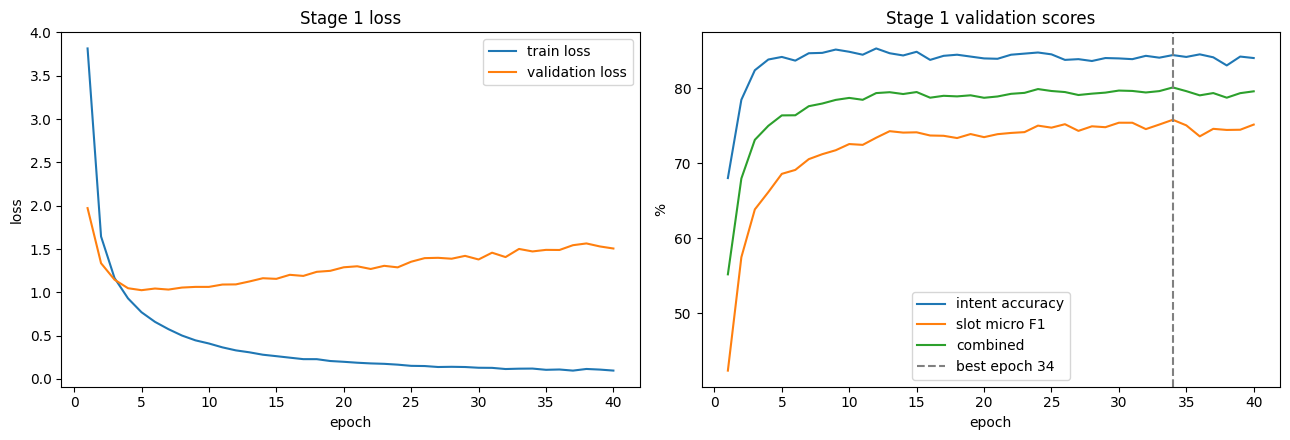

In [12]:
# Stage 1: per-epoch log and learning curves of the selected configuration
hist = pd.DataFrame(selected["history"])
print(hist.round({"train_loss": 4, "val_loss": 4, "val_intent_acc": 2, "val_slot_f1": 2,
                  "val_combined": 2, "epoch_time_s": 1}).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(hist["epoch"], hist["train_loss"], label="train loss")
axes[0].plot(hist["epoch"], hist["val_loss"], label="validation loss")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].set_title("Stage 1 loss"); axes[0].legend()
for col, label in [("val_intent_acc", "intent accuracy"), ("val_slot_f1", "slot micro F1"),
                   ("val_combined", "combined")]:
    axes[1].plot(hist["epoch"], hist[col], label=label)
axes[1].axvline(sel_best["epoch"], color="grey", linestyle="--", label=f"best epoch {sel_best['epoch']}")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("%"); axes[1].set_title("Stage 1 validation scores"); axes[1].legend()
plt.tight_layout(); plt.show()

### Stage 1 — final evaluation of the saved checkpoint

The checkpoint is reloaded from disk into a fresh model and evaluated without further training. The validation
score must equal the best validation score printed above; the test split is scored once, here.

In [13]:
ckpt = torch.load(S1_CKPT_PATH, map_location=DEVICE, weights_only=False)
assert ckpt["word2id"] == word2id and ckpt["intent2id"] == intent2id and ckpt["slot2id"] == slot2id

final_model = JointTransformer(np.zeros((len(word2id), GLOVE_DIM), dtype=np.float32),
                               len(intent2id), len(slot2id), ckpt["cfg"]).to(DEVICE)
final_model.load_state_dict(ckpt["model_state"])
final_total, final_trainable = count_params(final_model)
assert final_total <= 20_000_000


def s1_run_split(split):
    return s1_evaluate(final_model, split)


val_res = s1_run_split("dev")
print(f"Loaded checkpoint: {os.path.relpath(S1_CKPT_PATH, ROOT)} (epoch {ckpt['epoch']}, lr {ckpt['cfg']['lr']:.0e}, "
      f"layers {ckpt['cfg']['layers']})")
assert val_res["combined"] == ckpt["val_scores"]["combined"], "Reloaded validation score differs"
print("Reloaded validation score matches the best validation score from training.")
test_res = s1_run_split("test")                                                 # the single Stage-1 test evaluation
print(f"Validation | intent acc: {val_res['intent_acc']:.2f} | slot F1: {val_res['slot_f1']:.2f} | "
      f"combined: {val_res['combined']:.2f}")
print(f"Test       | intent acc: {test_res['intent_acc']:.2f} | slot F1: {test_res['slot_f1']:.2f} | "
      f"combined: {test_res['combined']:.2f}")

STAGE1 = {"total_params": final_total, "trainable_params": final_trainable,
          "epochs": f"{BASE_CFG['epochs']} (selected: {ckpt['epoch']})", "dev": val_res, "test": test_res}

Loaded checkpoint: checkpoints/stage1/joint_transformer_best.pt (epoch 34, lr 5e-04, layers 2)
Reloaded validation score matches the best validation score from training.


Validation | intent acc: 84.41 | slot F1: 75.79 | combined: 80.10
Test       | intent acc: 83.22 | slot F1: 72.85 | combined: 78.03


## 6. Stage 2 — AI-enhanced system

**One system, both tasks.** The Stage-2 system is an ensemble of six *joint* networks. Every member reads only `utt`
and predicts **both** the intent and the slots from one shared encoder; the ensemble averages them. No member is
trained for only one task.

**Member network (`JointNet`)**

| Part | Detail |
|---|---|
| Inputs per unit | frozen GloVe⊕fastText 600-d (shared by all members, counted once) ⊕ trainable 100-d unit embedding (word dropout) ⊕ char-CNN 100-d ⊕ hashed char-n-gram 50-d → linear projection to *C* |
| Encoder (varies) | **GLU**: 6 residual gated dilated convolutions (dilations 1,2,4,8,1,2), C=192 · **BiLSTM**: 2 layers, C=256 · **Transformer**: 4 pre-LN layers, 4 heads, T5 relative-position bias, C=192 |
| Intent head | mean ⊕ max pooling → MLP → 60 intents; **hierarchical**: log p(intent) + log p(scenario of that intent) from a separate 18-way scenario classifier |
| Intent → slots | the soft intent prediction is embedded and added to every token state (slots conditioned on intent) |
| Slot head (varies) | **CRF**: per-word BIO emissions + CRF with transitions that make invalid BIO sequences impossible, Viterbi decoding · **Span**: every span up to 10 words is classified into 55 types or "none"; exact best set of non-overlapping spans by dynamic programming. Span members also feed the slot-type evidence back into the intent head |

**Loss**: intent CE (label smoothing 0.1) + 0.5 × scenario CE + slot loss (CRF negative log-likelihood, or span CE);
span members add 0.5 × CE on the intent logits before slot feedback.
**Optimizer**: AdamW (lr 1e-3, 5e-4 for the Transformer; weight decay 0.01), 1 warm-up epoch then cosine decay,
gradient clipping 5, batch 32, 40 epochs, dropout 0.4 (0.3 Transformer). From epoch 30 a running weight average (SWA)
is also evaluated; per member, the raw or SWA weights with the best **dev combined** score are kept.

**Ensemble (6 members)**: 2 × GLU-CRF, 2 × GLU-span, 1 × BiLSTM-CRF, 1 × Transformer-CRF (different seeds).
Intent = mean of member probabilities. Slots = each member votes for the spans it decoded; spans with vote share
≥ threshold are kept, highest vote first, skipping overlaps. The threshold is chosen on dev.

**What changed from Stage 1 and why** — see the report; in short: richer OOV-robust inputs (char-CNN, char n-grams,
two frozen word-vector tables), BIO-constrained CRF / span decoding to get exact spans, hierarchical and
intent-conditioned heads to tie the two tasks together, SWA and an ensemble of different encoders to reduce variance.

In [14]:
# ---------------------------------------------------------------------- CRF with hard BIO constraints
def crf_log_partition(em, mask, trans, start, end):
    alpha = start + em[:, 0]
    for t in range(1, em.size(1)):
        nxt = torch.logsumexp(alpha.unsqueeze(2) + trans.unsqueeze(0), dim=1) + em[:, t]
        alpha = torch.where(mask[:, t].unsqueeze(1), nxt, alpha)
    return torch.logsumexp(alpha + end, dim=1)


def crf_path_score(em, tags, mask, trans, start, end):
    maskf = mask.float()
    s = start[tags[:, 0]] + (em.gather(2, tags.unsqueeze(2)).squeeze(2) * maskf).sum(1)
    s = s + (trans[tags[:, :-1], tags[:, 1:]] * maskf[:, 1:]).sum(1)
    last = tags.gather(1, (mask.sum(1) - 1).unsqueeze(1)).squeeze(1)
    return s + end[last]


def crf_viterbi(em, mask, trans, start, end):
    score_, history = start + em[:, 0], []
    for t in range(1, em.size(1)):
        best, idx = (score_.unsqueeze(2) + trans.unsqueeze(0)).max(dim=1)
        score_ = torch.where(mask[:, t].unsqueeze(1), best + em[:, t], score_)
        history.append(idx)
    score_ = score_ + end
    _, last = score_.max(dim=1)
    hist = torch.stack(history, 1).cpu() if history else None
    last, lengths = last.cpu().tolist(), mask.sum(1).cpu().tolist()
    paths = []
    for b, L in enumerate(lengths):
        path = [last[b]]
        for t in range(L - 1, 0, -1):
            path.append(int(hist[b, t - 1, path[-1]]))
        paths.append(path[::-1])
    return paths


def bio_constraints(tag_itos):
    # I-x may only follow B-x or I-x, and a sequence may not start with I-x
    n = len(tag_itos)
    allowed, start_ok = torch.ones(n, n, dtype=torch.bool), torch.ones(n, dtype=torch.bool)
    for j, tj in enumerate(tag_itos):
        if tj.startswith("I-"):
            start_ok[j] = False
            for i, ti in enumerate(tag_itos):
                allowed[i, j] = ti[2:] == tj[2:] and ti != "O"
    return allowed, start_ok


class CRF(nn.Module):
    def __init__(self, n_tags, constraints):
        super().__init__()
        self.trans = nn.Parameter(torch.zeros(n_tags, n_tags))
        self.start = nn.Parameter(torch.zeros(n_tags))
        self.end = nn.Parameter(torch.zeros(n_tags))
        allowed, start_ok = constraints
        self.register_buffer("pen_trans", (~allowed).float() * -1e4)
        self.register_buffer("pen_start", (~start_ok).float() * -1e4)

    def potentials(self):
        return self.trans + self.pen_trans, self.start + self.pen_start, self.end

    def nll(self, em, tags, mask):
        tr, st, en = self.potentials()
        return crf_log_partition(em, mask, tr, st, en) - crf_path_score(em, tags, mask, tr, st, en)


# ---------------------------------------------------------------------- span head helpers
def gold_span_grid(tags, lengths, labels, max_span=MAX_SPAN):
    # gold slot type (0 = none) for every (start, width) cell
    B, T = tags.shape
    grid = torch.zeros(B, T * max_span, dtype=torch.long)
    tags = tags.cpu()
    for b, L in enumerate(lengths.tolist()):
        start, cur = None, 0
        for t in range(L + 1):
            tid = int(tags[b, t]) if t < L else 0
            typ = int(labels.tag_type[tid])
            if cur and (typ != cur or labels.tag_is_b[tid]):
                if t - start <= max_span:
                    grid[b, start * max_span + (t - 1 - start)] = cur
                cur = 0
            if typ and not cur:
                start, cur = t, typ
    return grid


def best_spans(gains, max_span=MAX_SPAN):
    # exact choice of non-overlapping spans with the largest total positive gain (weighted interval scheduling)
    T = len(gains)
    best, choice = [0.0] * (T + 1), [None] * (T + 1)
    for end in range(1, T + 1):
        best[end], choice[end] = best[end - 1], None
        for w in range(min(max_span, end)):
            i = end - 1 - w
            g = gains[i][w]
            if g > 0 and best[i] + g > best[end]:
                best[end], choice[end] = best[i] + g, (i, w)
    spans, end = [], T
    while end > 0:
        if choice[end] is None:
            end -= 1
        else:
            i, w = choice[end]
            spans.append((i, w))
            end = i
    return spans[::-1]


def paths_to_spans(path, labels):
    # BIO tag ids -> {(start, width, type_id): 1.0}; an I-x that does not continue an x span starts a new span
    spans, start, cur = {}, None, 0
    for t, tid in enumerate(list(path) + [0]):
        typ = int(labels.tag_type[tid])
        if cur and (typ != cur or labels.tag_is_b[tid]):
            spans[(start, t - 1 - start, cur - 1)] = 1.0
            cur = 0
        if typ and not cur:
            start, cur = t, typ
    return spans


def decode_span_logits(span_logits, valid, lengths):
    logp = F.log_softmax(span_logits.float(), 2).cpu()
    best_type = logp[:, :, 1:].argmax(2) + 1
    gain = (logp.gather(2, best_type.unsqueeze(2)).squeeze(2) - logp[:, :, 0]).masked_fill(~valid.cpu(), -1.0)
    out = []
    for b, L in enumerate(lengths.tolist()):
        chosen = best_spans(gain[b].view(-1, MAX_SPAN)[:L].tolist())
        out.append({(i, w, int(best_type[b, i * MAX_SPAN + w]) - 1): 1.0 for i, w in chosen})
    return out


def spans_to_slot_labels(span_dict, n_words, labels):
    # {(start, width, type_id)} -> one MASSIVE slot label per word ('Other' outside a slot)
    out = ["Other"] * n_words
    for (i, w, k) in span_dict:
        out[i:i + w + 1] = [labels.slot_types[k]] * (w + 1)
    return out


def spans_to_text(span_dict, tokens, labels):
    # {(start, width, type_id)} -> list of (slot_type, span_text) in word order
    return [(labels.slot_types[k], " ".join(tokens[i:i + w + 1])) for (i, w, k) in sorted(span_dict)]

In [15]:
# ---------------------------------------------------------------------- input layer pieces and encoders
class SeqConv(nn.Module):
    def __init__(self, c_in, c_out, width=3, dilation=1):
        super().__init__()
        self.width, self.dilation = width, dilation
        self.lin = nn.Linear(width * c_in, c_out)

    def forward(self, x):
        T, pad = x.size(1), (self.width // 2) * self.dilation
        xp = F.pad(x, (0, 0, pad, pad))
        return self.lin(torch.cat([xp[:, i * self.dilation:i * self.dilation + T] for i in range(self.width)], dim=2))


class CharCNN(nn.Module):
    def __init__(self, n_chars, char_dim=50, filters=100, width=3):
        super().__init__()
        self.emb = nn.Embedding(n_chars, char_dim, padding_idx=0)
        self.conv = SeqConv(char_dim, filters, width)
        self.out_dim = filters

    def forward(self, chars):
        B, T, C = chars.shape
        flat = chars.view(B * T, C)
        h = self.conv(self.emb(flat)).masked_fill((flat == 0).unsqueeze(2), -1e4).max(dim=1).values
        return torch.tanh(h).view(B, T, -1)


class GLUBlock(nn.Module):
    def __init__(self, channels, dilation, width=3, dropout=0.3):
        super().__init__()
        self.conv = SeqConv(channels, 2 * channels, width, dilation)
        self.norm = nn.LayerNorm(channels)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, m):
        return self.norm(x + self.drop(F.glu(self.conv(x), dim=2))) * m


class GLUEncoder(nn.Module):
    # residual gated dilated convolutions
    def __init__(self, cfg):
        super().__init__()
        self.blocks = nn.ModuleList([GLUBlock(cfg["channels"], d, 3, cfg["dropout"]) for d in cfg["dilations"]])

    def forward(self, x, umask):
        m = umask.unsqueeze(2).float()
        for blk in self.blocks:
            x = blk(x, m)
        return x


class LSTMEncoder(nn.Module):
    # 2-layer BiLSTM with a residual connection
    def __init__(self, cfg):
        super().__init__()
        C = cfg["channels"]
        self.rnn = nn.LSTM(C, C // 2, num_layers=cfg.get("rnn_layers", 2), batch_first=True, bidirectional=True,
                           dropout=cfg["dropout"])
        self.norm = nn.LayerNorm(C)
        self.drop = nn.Dropout(cfg["dropout"])

    def forward(self, x, umask):
        lengths = umask.sum(1).cpu()
        packed = nn.utils.rnn.pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        h, _ = self.rnn(packed)
        h, _ = nn.utils.rnn.pad_packed_sequence(h, batch_first=True, total_length=x.size(1))
        return self.norm(x + self.drop(h)) * umask.unsqueeze(2).float()


def rel_bucket(rel, num_buckets=32, max_distance=64):
    # T5-style bidirectional relative-position buckets
    nb = num_buckets // 2
    ret = (rel > 0).long() * nb
    n = rel.abs()
    max_exact = nb // 2
    large = max_exact + (torch.log(n.float().clamp(min=1) / max_exact) / math.log(max_distance / max_exact)
                         * (nb - max_exact)).long()
    return ret + torch.where(n < max_exact, n, large.clamp(max=nb - 1))


class TBlock(nn.Module):
    def __init__(self, d, heads, ffn, dropout, attn_dropout):
        super().__init__()
        self.h, self.dh = heads, d // heads
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv, self.out = nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.ff = nn.Sequential(nn.Linear(d, ffn), nn.GELU(), nn.Dropout(dropout), nn.Linear(ffn, d))
        self.drop = nn.Dropout(dropout)
        self.attn_dropout = attn_dropout

    def forward(self, x, bias):
        B, U, D = x.shape
        q, k, v = self.qkv(self.ln1(x)).view(B, U, 3, self.h, self.dh).permute(2, 0, 3, 1, 4)
        a = F.scaled_dot_product_attention(q, k, v, attn_mask=bias,
                                           dropout_p=self.attn_dropout if self.training else 0.0)
        x = x + self.drop(self.out(a.transpose(1, 2).reshape(B, U, D)))
        return x + self.drop(self.ff(self.ln2(x)))


class TransformerEncoder(nn.Module):
    # pre-LN Transformer with learned relative-position biases
    def __init__(self, cfg):
        super().__init__()
        C, H = cfg["channels"], cfg.get("heads", 4)
        self.rel = nn.Embedding(32, H)
        self.layers = nn.ModuleList([TBlock(C, H, cfg.get("ffn", 4 * C), cfg["dropout"], 0.1)
                                     for _ in range(cfg.get("layers", 4))])
        self.norm = nn.LayerNorm(C)

    def forward(self, x, umask):
        U = x.size(1)
        pos = torch.arange(U, device=x.device)
        bias = self.rel(rel_bucket(pos[None, :] - pos[:, None])).permute(2, 0, 1).unsqueeze(0)   # (1, H, U, U)
        bias = bias + (~umask).float()[:, None, None, :] * -1e4
        for layer in self.layers:
            x = layer(x, bias)
        return self.norm(x) * umask.unsqueeze(2).float()


ENCODERS = {"glu": GLUEncoder, "lstm": LSTMEncoder, "transformer": TransformerEncoder}


def masked_mean_max(h, mask):
    m = mask.unsqueeze(2).float()
    mean = (h * m).sum(1) / m.sum(1).clamp(min=1)
    mx = h.masked_fill(m == 0, -1e4).max(1).values
    return torch.cat([mean, mx], dim=1)

In [16]:
class JointNet(nn.Module):
    # One ensemble member: input layer -> encoder -> intent (+ scenario) head and a slot head ('crf' or 'span').
    # Both tasks are predicted by this single network from one shared encoder.

    def __init__(self, cfg, feats, labels, frozen):
        super().__init__()
        self.cfg, self.labels, C = cfg, labels, cfg["channels"]
        n_types = len(labels.slot_types)
        self.frozen = frozen                                    # shared, frozen GloVe + fastText table
        self.task_emb = nn.Embedding(len(feats["units"]), cfg["task_dim"], padding_idx=0)
        self.char_cnn = CharCNN(len(feats["chars"]))
        self.ngram = nn.Embedding(feats["ngram_buckets"] + 1, cfg["ngram_dim"], padding_idx=0)
        in_dim = frozen.embedding_dim + cfg["task_dim"] + self.char_cnn.out_dim + cfg["ngram_dim"]
        self.in_drop = nn.Dropout(cfg["dropout"])
        self.proj = nn.Linear(in_dim, C)
        self.encoder = ENCODERS[cfg["encoder"]](cfg)
        self.drop = nn.Dropout(cfg["dropout"])
        self.intent_hidden = nn.Sequential(nn.Linear(2 * C, C), nn.ReLU(), nn.Dropout(cfg["dropout"]))
        self.intent_out = nn.Linear(C, len(labels.intents))
        self.scen_out = nn.Linear(C, len(labels.scenarios))
        self.intent_label_emb = nn.Embedding(len(labels.intents), C)
        if cfg["head"] == "crf":
            self.slot_head = nn.Sequential(nn.Linear(C, C), nn.ReLU(), nn.Dropout(cfg["dropout"]),
                                           nn.Linear(C, len(labels.tags)))
            self.crf = CRF(len(labels.tags), bio_constraints(labels.tags.itos))
        else:
            self.width_emb = nn.Embedding(MAX_SPAN, cfg["width_dim"])
            self.span_head = nn.Sequential(nn.Linear(3 * C + cfg["width_dim"], C), nn.ReLU(),
                                           nn.Dropout(cfg["dropout"]), nn.Linear(C, n_types + 1))
            self.slot_to_intent = nn.Linear(n_types, C)
        self.register_buffer("drop_p", feats["drop_p"])
        self.register_buffer("i2s", labels.i2s.clone())

    def trunk(self, batch):
        ids, umask = batch["units"], batch["units"] != 0
        m = umask.unsqueeze(2).float()
        tids = ids
        if self.training:              # frequency-based word dropout on the trainable embedding only
            tids = ids.masked_fill((torch.rand(ids.shape, device=ids.device) < self.drop_p[ids]) & umask, 1)
        g = batch["grams"]
        parts = [self.frozen(batch["frozen"]), self.task_emb(tids), self.char_cnn(batch["chars"]),
                 self.ngram(g).sum(2) / (g != 0).sum(2, keepdim=True).clamp(min=1)]
        x = self.proj(self.in_drop(torch.cat(parts, dim=2))) * m
        x = self.encoder(x, umask)
        pooled = masked_mean_max(x, umask)
        T = int(batch["lengths"].max())
        h = x.gather(1, batch["first"][:, :T].unsqueeze(2).expand(-1, -1, x.size(2)))   # first unit of each word
        tmask = torch.arange(T, device=x.device).unsqueeze(0) < batch["lengths"].to(x.device).unsqueeze(1)
        return h, tmask, pooled

    def compute(self, batch):
        h, tmask, pooled = self.trunk(batch)
        z = self.intent_hidden(pooled)
        logits0 = self.intent_out(z)
        scen = self.scen_out(z)
        h = h + (F.softmax(logits0, 1) @ self.intent_label_emb.weight).unsqueeze(1)      # intent-aware slots
        out = {"mask": tmask, "scen_logits": scen, "logits0": logits0}
        if self.cfg["head"] == "crf":
            out["emissions"] = self.slot_head(self.drop(h))
            logits = logits0
        else:
            B, T, C = h.shape
            i = torch.arange(T, device=h.device).repeat_interleave(MAX_SPAN)
            w = torch.arange(MAX_SPAN, device=h.device).repeat(T)
            j = (i + w).clamp(max=T - 1)
            valid = (i + w < T).unsqueeze(0) & tmask.gather(1, j.unsqueeze(0).expand(B, -1))
            csum = torch.cat([torch.zeros(B, 1, C, device=h.device), h.cumsum(1)], dim=1)
            mean = (csum[:, j + 1] - csum[:, i]) / (w + 1).unsqueeze(0).unsqueeze(2).float()
            rep = [h[:, i], h[:, j], mean, self.width_emb(w).unsqueeze(0).expand(B, -1, -1)]
            span_logits = self.span_head(self.drop(torch.cat(rep, dim=2)))
            out["span_logits"], out["span_valid"] = span_logits, valid
            probs = F.softmax(span_logits, 2)[:, :, 1:] * valid.unsqueeze(2).float()
            logits = self.intent_out(self.drop(z + self.slot_to_intent(torch.log1p(probs.sum(1)))))
        # hierarchical intent: log p(intent) + log p(its scenario)
        out["intent_logits"] = F.log_softmax(logits, 1) + F.log_softmax(scen, 1)[:, self.i2s]
        return out

    def loss(self, batch, out):
        cfg, ls = self.cfg, self.cfg["label_smoothing"]
        loss = F.cross_entropy(out["intent_logits"], batch["intent"], label_smoothing=ls)
        loss = loss + cfg["scen_weight"] * F.cross_entropy(out["scen_logits"], batch["scenario"])
        T = out["mask"].size(1)
        if cfg["head"] == "crf":
            slot = self.crf.nll(out["emissions"], batch["tags"][:, :T], out["mask"]).mean()
        else:
            loss = loss + 0.5 * F.cross_entropy(out["logits0"], batch["intent"], label_smoothing=ls)
            grid = gold_span_grid(batch["tags"], batch["lengths"], self.labels)
            grid = grid[:, :out["span_logits"].size(1)].to(out["span_logits"].device)
            ce = F.cross_entropy(out["span_logits"].transpose(1, 2), grid, reduction="none")
            slot = (ce * out["span_valid"].float()).sum() / ce.size(0)
        return loss + cfg["slot_weight"] * slot

    @torch.no_grad()
    def predict(self, batch, out):
        # intent probabilities (B, 60) and, per utterance, {(start, width, type_id): 1.0}
        probs = F.softmax(out["intent_logits"], 1)
        if self.cfg["head"] == "crf":
            spans = [paths_to_spans(p, self.labels) for p in crf_viterbi(out["emissions"], out["mask"],
                                                                         *self.crf.potentials())]
        else:
            spans = decode_span_logits(out["span_logits"], out["span_valid"], batch["lengths"])
        return probs, spans

In [17]:
class MixedEnsemble:
    # Intent: mean of member probabilities. Slots: each member votes for every span it decoded; spans whose vote
    # share reaches `threshold` are kept, highest vote first (longer span on ties), skipping overlaps.
    def __init__(self, threshold=0.5):
        self.threshold = threshold

    def combine(self, member_probs, member_spans):
        M = len(member_probs)
        probs = sum(member_probs) / M
        spans = []
        for n in range(len(member_spans[0])):
            votes = Counter()
            for ms in member_spans:
                for key in ms[n]:
                    votes[key] += 1.0 / M
            chosen, used = {}, set()
            for (i, wd, k), v in sorted(votes.items(), key=lambda kv: (-kv[1], -kv[0][1], kv[0])):
                if v + 1e-9 < self.threshold:
                    break
                cover = set(range(i, i + wd + 1))
                if not cover & used:
                    chosen[(i, wd, k)] = v
                    used |= cover
            spans.append(chosen)
        return probs, spans


BASE = dict(encoder="glu", head="crf", channels=192, dilations=[1, 2, 4, 8, 1, 2], dropout=0.4, task_dim=100,
            ngram_dim=50, width_dim=32, scen_weight=0.5, label_smoothing=0.1, slot_weight=1.0, lr=1e-3,
            weight_decay=0.01, batch_size=32, max_epochs=40, warmup_epochs=1, swa_start=30, clip=5.0)
ARCHS = {
    "glu_crf": {},
    "glu_span": {"head": "span"},
    "lstm_crf": {"encoder": "lstm", "channels": 256},
    "tf_crf": {"encoder": "transformer", "layers": 4, "heads": 4, "ffn": 768, "dropout": 0.3, "lr": 5e-4},
}
MEMBERS = [("glu_crf", 42), ("glu_crf", 43), ("glu_span", 42), ("glu_span", 43), ("lstm_crf", 42), ("tf_crf", 42)]


def make_cfg(arch, seed):
    return {**BASE, **ARCHS[arch], "arch": arch, "seed": seed}


def member_tag(arch, seed):
    return f"{arch}_s{seed}"


def make_frozen(table):
    return nn.Embedding.from_pretrained(table.clone(), freeze=True, padding_idx=0)


# ---- total parameter count of the whole Stage-2 pipeline (frozen table counted once, all six members)
frozen_shared = make_frozen(feats["table"])
rows, member_params = [], 0
for arch, seed in MEMBERS:
    set_seed(seed)
    m = JointNet(make_cfg(arch, seed), feats, labels, frozen_shared)
    n = sum(p.numel() for p in m.parameters() if p.requires_grad)
    member_params += n
    rows.append({"member": member_tag(arch, seed), "encoder": m.cfg["encoder"], "slot head": m.cfg["head"],
                 "trainable params": n})
frozen_n = frozen_shared.weight.numel()
STAGE2_TOTAL, STAGE2_TRAINABLE = frozen_n + member_params, member_params
display(pd.DataFrame(rows).set_index("member"))
print(f"frozen word vectors (shared, counted once): {frozen_n:,}")
print(f"Stage-2 pipeline: total {STAGE2_TOTAL:,} parameters | trainable {STAGE2_TRAINABLE:,}")
assert STAGE2_TOTAL <= 20_000_000, "over the 20M cap"
print("within the 20M parameter cap")

,encoder,slot head,trainable params
member,,,
glu_crf_s42,glu,crf,2448770
glu_crf_s43,glu,crf,2448770
glu_span_s42,glu,span,2516556
glu_span_s43,glu,span,2516556
lstm_crf_s42,lstm,crf,2064642
tf_crf_s42,transformer,crf,2897026


frozen word vectors (shared, counted once): 3,522,600
Stage-2 pipeline: total 18,414,920 parameters | trainable 14,892,320
within the 20M parameter cap


## 7. Stage 2 — training and checkpoint selection

Each member is trained on the **train split only** for 40 epochs. After every epoch it is scored on dev (and, from
epoch 30, its SWA weights too); the weights with the highest **dev combined** score
(mean of intent accuracy and slot micro-F1) are saved to `checkpoints/stage2/<member>.pt`.
Epoch logs are kept in `logs/stage2/<member>.json`.

In [18]:
@torch.no_grad()
def member_outputs(model, batches):
    # intent probabilities (N, 60), span dicts in dataset order, average loss
    model.eval()
    probs, spans, tot, n = [], [], 0.0, 0
    for batch in batches:
        batch = to_device(batch)
        out = model.compute(batch)
        tot += model.loss(batch, out).item() * len(batch["lengths"])
        n += len(batch["lengths"])
        p, s = model.predict(batch, out)
        probs.append(p.cpu())
        spans += s
    return torch.cat(probs), spans, tot / n


def evaluate_outputs(probs, spans, examples):
    intents = [labels.intents.itos[i] for i in probs.argmax(1).tolist()]
    return score(intents, [spans_to_slot_labels(s, len(e["tokens"]), labels) for s, e in zip(spans, examples)],
                 examples)


def evaluate(model, batches, examples):
    probs, spans, loss = member_outputs(model, batches)
    return {"loss": loss, **evaluate_outputs(probs, spans, examples)}


def fit(model, cfg, train_enc, dev_batches, dev_examples, ckpt_path, tag):
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    steps_per_epoch = math.ceil(len(train_enc) / cfg["batch_size"])
    total_steps, warm = steps_per_epoch * cfg["max_epochs"], steps_per_epoch * cfg["warmup_epochs"]
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total_steps))))
    swa, swa_n = None, 0
    history, best = [], {"combined": -1.0}
    t_start = time.time()
    for epoch in range(1, cfg["max_epochs"] + 1):
        t0 = time.time()
        model.train()
        running, seen = 0.0, 0
        for batch in make_batches(train_enc, cfg["batch_size"], shuffle=True, seed=cfg["seed"] * 1000 + epoch):
            batch = to_device(batch)
            loss = model.loss(batch, model.compute(batch))
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(params, cfg["clip"])
            opt.step()
            sched.step()
            running += loss.item() * len(batch["lengths"])
            seen += len(batch["lengths"])
        dev = evaluate(model, dev_batches, dev_examples)
        candidates = [("raw", dev, None)]
        if epoch >= cfg["swa_start"]:                       # running average of the weights from epoch swa_start
            state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            if swa is None:
                swa = {k: v.clone() for k, v in state.items()}
            else:
                for k, v in state.items():
                    if v.dtype.is_floating_point:
                        swa[k].mul_(swa_n / (swa_n + 1)).add_(v, alpha=1 / (swa_n + 1))
            swa_n += 1
            model.load_state_dict(swa)
            candidates.append(("swa", evaluate(model, dev_batches, dev_examples), copy.deepcopy(swa)))
            model.load_state_dict(state)
        row = {"epoch": epoch, "train_loss": running / seen, "dev_loss": dev["loss"], "dev_intent_acc": dev["intent_acc"],
               "dev_slot_f1": dev["slot_f1"], "dev_combined": dev["combined"], "lr": opt.param_groups[0]["lr"],
               "epoch_time_s": time.time() - t0, "elapsed_s": time.time() - t_start}
        if len(candidates) > 1:
            s = candidates[1][1]
            row.update({"swa_dev_loss": s["loss"], "swa_intent_acc": s["intent_acc"], "swa_slot_f1": s["slot_f1"],
                        "swa_combined": s["combined"]})
        history.append(row)
        saved = ""
        for kind, res, state in candidates:
            if res["combined"] > best["combined"]:
                best = {**res, "epoch": epoch, "kind": kind}
                torch.save({"state": state if state is not None else model.state_dict(), "epoch": epoch, "kind": kind,
                            "dev": res, "config": cfg}, ckpt_path)
                saved = f"  <- saved ({kind})"
        swa_txt = f" | swa comb {row['swa_combined']:.2f}" if "swa_combined" in row else ""
        print(f"[{tag}] epoch {epoch:2d} | train loss {row['train_loss']:.4f} | dev loss {row['dev_loss']:.4f} | "
              f"intent {row['dev_intent_acc']:.2f} | slot F1 {row['dev_slot_f1']:.2f} | comb {row['dev_combined']:.2f}"
              f"{swa_txt} | {row['epoch_time_s']:.1f}s (total {row['elapsed_s'] / 60:.1f} min){saved}", flush=True)
    best["train_time_s"] = time.time() - t_start
    return history, best

In [19]:
histories, bests, member_dev = {}, {}, {}
dev_batches = eval_batches["dev"]
for arch, seed in MEMBERS:
    tag, cfg = member_tag(arch, seed), make_cfg(arch, seed)
    ckpt = os.path.join(CKPT_DIR, f"{tag}.pt")
    print(f"\n===== {tag} | {json.dumps(cfg)}", flush=True)
    set_seed(seed)
    model = JointNet(cfg, feats, labels, make_frozen(feats["table"])).to(DEVICE)
    hist, best = fit(model, cfg, enc["train"], dev_batches, data["dev"], ckpt, tag)
    # keep the selected member's dev outputs; check the saved file reproduces the selected dev score
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE, weights_only=False)["state"])
    probs, spans, _ = member_outputs(model, dev_batches)
    res = evaluate_outputs(probs, spans, data["dev"])
    assert (res["intent_acc"], res["slot_f1"]) == (best["intent_acc"], best["slot_f1"])
    histories[tag], bests[tag], member_dev[tag] = hist, best, (probs, spans)
    json.dump({"tag": tag, "config": cfg, "history": hist, "best": best}, open(os.path.join(LOG_DIR, f"{tag}.json"), "w"),
              indent=1)
    print(f"[{tag}] best epoch {best['epoch']} ({best['kind']} weights) | dev intent {best['intent_acc']:.2f} | "
          f"slot F1 {best['slot_f1']:.2f} | combined {best['combined']:.2f} | {best['train_time_s'] / 60:.1f} min | {ckpt}")
    del model
    torch.cuda.empty_cache()


===== glu_crf_s42 | {"encoder": "glu", "head": "crf", "channels": 192, "dilations": [1, 2, 4, 8, 1, 2], "dropout": 0.4, "task_dim": 100, "ngram_dim": 50, "width_dim": 32, "scen_weight": 0.5, "label_smoothing": 0.1, "slot_weight": 1.0, "lr": 0.001, "weight_decay": 0.01, "batch_size": 32, "max_epochs": 40, "warmup_epochs": 1, "swa_start": 30, "clip": 5.0, "arch": "glu_crf", "seed": 42}


[glu_crf_s42] epoch  1 | train loss 11.5953 | dev loss 4.7117 | intent 50.07 | slot F1 63.86 | comb 56.97 | 9.0s (total 0.2 min)  <- saved (raw)


[glu_crf_s42] epoch  2 | train loss 4.8249 | dev loss 3.4713 | intent 72.80 | slot F1 72.28 | comb 72.54 | 5.9s (total 0.3 min)  <- saved (raw)


[glu_crf_s42] epoch  3 | train loss 3.8858 | dev loss 3.1386 | intent 78.46 | slot F1 76.05 | comb 77.25 | 6.8s (total 0.4 min)  <- saved (raw)


[glu_crf_s42] epoch  4 | train loss 3.4082 | dev loss 3.0095 | intent 80.96 | slot F1 77.01 | comb 78.99 | 8.5s (total 0.5 min)  <- saved (raw)


[glu_crf_s42] epoch  5 | train loss 3.1424 | dev loss 2.9118 | intent 82.69 | slot F1 78.19 | comb 80.44 | 6.8s (total 0.6 min)  <- saved (raw)


... (237 outputs left out)

[tf_crf_s42] epoch 38 | train loss 1.2392 | dev loss 3.0738 | intent 86.87 | slot F1 80.98 | comb 83.92 | swa comb 83.91 | 13.9s (total 8.3 min)


[tf_crf_s42] epoch 39 | train loss 1.2574 | dev loss 3.0733 | intent 86.92 | slot F1 81.01 | comb 83.96 | swa comb 83.93 | 14.4s (total 8.5 min)


[tf_crf_s42] epoch 40 | train loss 1.2591 | dev loss 3.0732 | intent 86.92 | slot F1 81.01 | comb 83.96 | swa comb 83.92 | 12.5s (total 8.8 min)


[tf_crf_s42] best epoch 26 (raw weights) | dev intent 86.82 | slot F1 81.36 | combined 84.09 | 8.8 min | /mnt/hdd2/zhengrong/SC4002-submission/checkpoints/stage2/tf_crf_s42.pt


### Learning curves (per member: losses and dev scores per epoch)

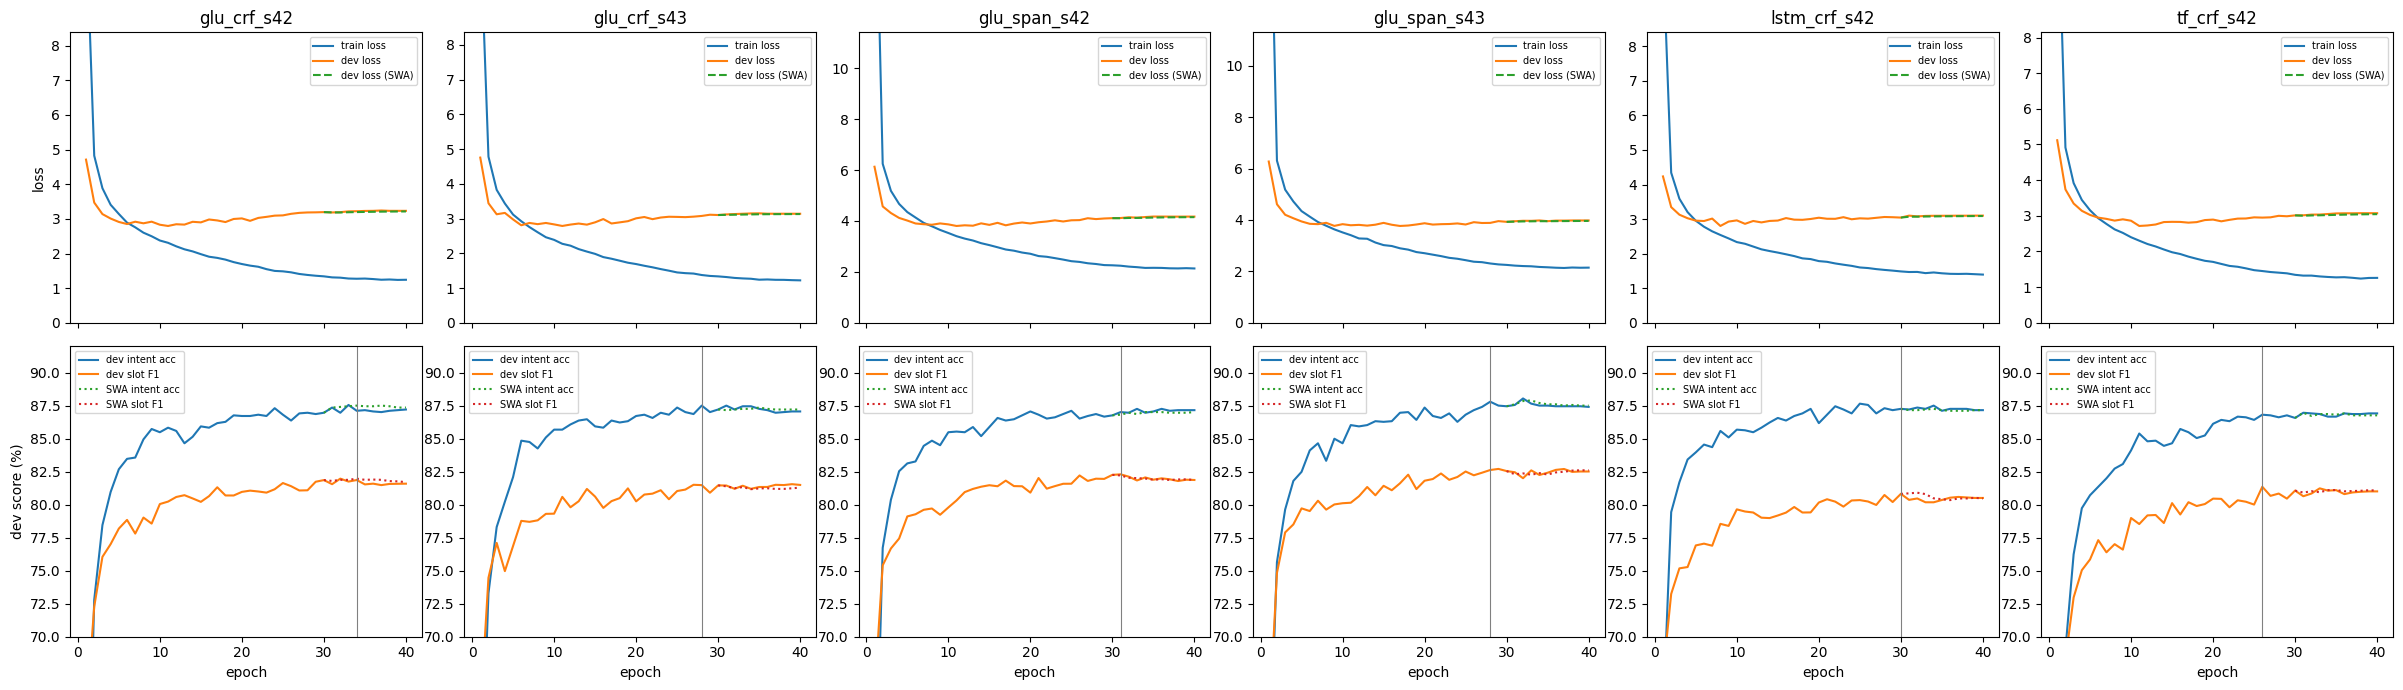

In [20]:
fig, axes = plt.subplots(2, len(MEMBERS), figsize=(4 * len(MEMBERS), 7), sharex=True)
for c, tag in enumerate(histories):
    h = pd.DataFrame(histories[tag])
    ax = axes[0, c]
    ax.plot(h.epoch, h.train_loss, label="train loss")
    ax.plot(h.epoch, h.dev_loss, label="dev loss")
    if "swa_dev_loss" in h:
        ax.plot(h.epoch, h.swa_dev_loss, "--", label="dev loss (SWA)")
    ax.set_title(tag)
    ax.set_ylim(0, max(2.0, float(h.dev_loss.min()) * 3))
    ax.legend(fontsize=7)
    ax = axes[1, c]
    ax.plot(h.epoch, h.dev_intent_acc, label="dev intent acc")
    ax.plot(h.epoch, h.dev_slot_f1, label="dev slot F1")
    if "swa_combined" in h:
        ax.plot(h.epoch, h.swa_intent_acc, ":", label="SWA intent acc")
        ax.plot(h.epoch, h.swa_slot_f1, ":", label="SWA slot F1")
    b = bests[tag]
    ax.axvline(b["epoch"], color="grey", lw=0.8)
    ax.set_ylim(70, 92)
    ax.set_xlabel("epoch")
    ax.legend(fontsize=7)
axes[0, 0].set_ylabel("loss")
axes[1, 0].set_ylabel("dev score (%)")
plt.tight_layout()
plt.show()

### Ensemble selection on dev

The six selected member checkpoints are combined; the slot vote threshold is chosen on **dev** only
(highest dev combined score).

In [21]:
tags = list(member_dev)
sweep = {}
for thr in (0.3, 0.4, 0.5, 0.6, 0.7):
    p, s = MixedEnsemble(thr).combine([member_dev[t][0] for t in tags], [member_dev[t][1] for t in tags])
    sweep[thr] = evaluate_outputs(p, s, data["dev"])
display(pd.DataFrame({thr: {k: round(r[k], 2) for k in ("intent_acc", "slot_f1", "combined")} for thr, r in sweep.items()}).T
        .rename_axis("vote threshold"))
THRESHOLD = max(sweep, key=lambda t: sweep[t]["combined"])
selected_dev = sweep[THRESHOLD]

member_table = pd.DataFrame([{"member": t, "selected epoch": bests[t]["epoch"], "weights": bests[t]["kind"],
                              "dev intent acc": round(bests[t]["intent_acc"], 2),
                              "dev slot F1": round(bests[t]["slot_f1"], 2),
                              "dev combined": round(bests[t]["combined"], 2),
                              "train time (min)": round(bests[t]["train_time_s"] / 60, 1),
                              "checkpoint": os.path.relpath(os.path.join(CKPT_DIR, f"{t}.pt"), ROOT)} for t in tags])
display(member_table.set_index("member"))
ENSEMBLE_SPEC = {"members": tags, "threshold": THRESHOLD, "dev": selected_dev,
                 "epochs": {t: bests[t]["epoch"] for t in tags}}
json.dump(ENSEMBLE_SPEC, open(os.path.join(CKPT_DIR, "ensemble.json"), "w"), indent=1)
print(f"SELECTED Stage-2 checkpoint: ensemble of {len(tags)} members, vote threshold {THRESHOLD} | "
      f"dev intent {selected_dev['intent_acc']:.2f} | slot F1 {selected_dev['slot_f1']:.2f} | "
      f"combined {selected_dev['combined']:.2f}")
print("checkpoint files:", os.path.relpath(os.path.join(CKPT_DIR, "ensemble.json"), ROOT), "+",
      ", ".join(f"{t}.pt" for t in tags))

,intent_acc,slot_f1,combined
vote threshold,,,
0.3,88.54,82.72,85.63
0.4,88.54,83.84,86.19
0.5,88.54,83.84,86.19
0.6,88.54,84.39,86.47
0.7,88.54,83.67,86.11


,selected epoch,weights,dev intent acc,dev slot F1,dev combined,train time (min),checkpoint
member,,,,,,,
glu_crf_s42,34,swa,87.51,81.97,84.74,6.2,checkpoints/stage2/glu_crf_s42.pt
glu_crf_s43,28,raw,87.51,81.48,84.49,6.6,checkpoints/stage2/glu_crf_s43.pt
glu_span_s42,31,raw,87.01,82.30,84.66,7.1,checkpoints/stage2/glu_span_s42.pt
glu_span_s43,28,raw,87.80,82.63,85.21,7.0,checkpoints/stage2/glu_span_s43.pt
lstm_crf_s42,30,raw,87.26,80.82,84.04,6.8,checkpoints/stage2/lstm_crf_s42.pt
tf_crf_s42,26,raw,86.82,81.36,84.09,8.8,checkpoints/stage2/tf_crf_s42.pt


SELECTED Stage-2 checkpoint: ensemble of 6 members, vote threshold 0.6 | dev intent 88.54 | slot F1 84.39 | combined 86.47
checkpoint files: checkpoints/stage2/ensemble.json + glu_crf_s42.pt, glu_crf_s43.pt, glu_span_s42.pt, glu_span_s43.pt, lstm_crf_s42.pt, tf_crf_s42.pt


## 8. Stage 2 — final evaluation of the frozen checkpoint

No further training. The ensemble specification and every member checkpoint are **reloaded from disk** into fresh
networks (the frozen word-vector table is also restored from the checkpoints). The reloaded system must reproduce
the selected dev score exactly; only then is the test split evaluated — once.

In [22]:
spec = json.load(open(os.path.join(CKPT_DIR, "ensemble.json")))
frozen_reload = make_frozen(torch.zeros_like(feats["table"])).to(DEVICE)       # values come from the checkpoints
final_members = []
for t in spec["members"]:
    ck = torch.load(os.path.join(CKPT_DIR, f"{t}.pt"), map_location=DEVICE, weights_only=False)
    m = JointNet(ck["config"], feats, labels, frozen_reload).to(DEVICE)
    m.load_state_dict(ck["state"])
    m.eval()
    final_members.append(m)
ensemble = MixedEnsemble(spec["threshold"])

shared = {id(p) for p in frozen_reload.parameters()}
reload_total = frozen_reload.weight.numel() + sum(p.numel() for m in final_members for p in m.parameters()
                                                  if id(p) not in shared)
assert reload_total == STAGE2_TOTAL


def run_ensemble(split):
    outs = [member_outputs(m, eval_batches[split])[:2] for m in final_members]
    p, s = ensemble.combine([o[0] for o in outs], [o[1] for o in outs])
    return p, s, evaluate_outputs(p, s, data[split])


_, _, final_dev = run_ensemble("dev")
for k in ("intent_acc", "slot_f1", "exact_match"):
    assert final_dev[k] == spec["dev"][k], f"reloaded ensemble differs from the selected dev result on {k}"
print(f"Validation (reloaded) | intent accuracy {final_dev['intent_acc']:.2f} | slot micro-F1 {final_dev['slot_f1']:.2f}"
      f" | combined {final_dev['combined']:.2f}  == selected dev score")

test_probs, test_spans, final_test = run_ensemble("test")                       # the single test evaluation
print(f"Test                  | intent accuracy {final_test['intent_acc']:.2f} | slot micro-F1 {final_test['slot_f1']:.2f}"
      f" | exact match {final_test['exact_match']:.2f}")

Validation (reloaded) | intent accuracy 88.54 | slot micro-F1 84.39 | combined 86.47  == selected dev score


Test                  | intent accuracy 87.42 | slot micro-F1 82.23 | exact match 70.04


## 9. Results table

In [23]:
STAGE2 = {"total_params": STAGE2_TOTAL, "trainable_params": STAGE2_TRAINABLE,
          "epochs": f"{BASE['max_epochs']} per member (selected: {'/'.join(str(e) for e in spec['epochs'].values())})",
          "dev": final_dev, "test": final_test}
rows = []
for name, s in (("Stage-1 system", STAGE1), ("Stage-2 system", STAGE2)):
    if not s:
        continue
    for split in ("dev", "test"):
        rows.append({"Model version": name, "Split": "Validation" if split == "dev" else "Test",
                     "Total # parameters": f"{s['total_params']:,}", "Total # trainable parameters": f"{s['trainable_params']:,}",
                     "Intent accuracy (%)": f"{s[split]['intent_acc']:.2f}", "Slot micro-F1 (%)": f"{s[split]['slot_f1']:.2f}",
                     "Number of epochs": s["epochs"]})
display(pd.DataFrame(rows))

,Model version,Split,Total # parameters,Total # trainable parameters,Intent accuracy (%),Slot micro-F1 (%),Number of epochs
0,Stage-1 system,Validation,"1,924,939","1,924,939",84.41,75.79,40 (selected: 34)
1,Stage-1 system,Test,"1,924,939","1,924,939",83.22,72.85,40 (selected: 34)
2,Stage-2 system,Validation,"18,414,920","14,892,320",88.54,84.39,40 per member (selected: 34/28/31/28/30/26)
3,Stage-2 system,Test,"18,414,920","14,892,320",87.42,82.23,40 per member (selected: 34/28/31/28/30/26)


## 10. Stage 2 — error analysis (test predictions of the frozen system)

Done after the single test evaluation; nothing here feeds back into the model.

In [24]:
seen_values = {(t, s) for e in data["train"] for t, s in e["gold_spans"]}
pred_text = [set(spans_to_text(s, e["tokens"], labels)) for s, e in zip(test_spans, data["test"])]
pred_int = [labels.intents.itos[i] for i in test_probs.argmax(1).tolist()]
pred_lab = [spans_to_slot_labels(s, len(e["tokens"]), labels) for s, e in zip(test_spans, data["test"])]

# slot recall by whether the gold (type, value) occurs in train, and by span length
rec = {"seen in train": [0, 0], "unseen in train": [0, 0]}
by_len = {}
for e, pred in zip(data["test"], pred_text):
    for g in e["gold_spans"]:
        k = "seen in train" if g in seen_values else "unseen in train"
        rec[k][0] += g in pred
        rec[k][1] += 1
        L = min(len(g[1].split()), 4)
        by_len.setdefault(L, [0, 0])
        by_len[L][0] += g in pred
        by_len[L][1] += 1
display(pd.DataFrame([{"gold slots": k, "count": n, "recall (%)": round(100 * h / n, 1)} for k, (h, n) in rec.items()]))
display(pd.DataFrame([{"span length (words)": ("4+" if L == 4 else L), "count": n, "recall (%)": round(100 * h / n, 1)}
                      for L, (h, n) in sorted(by_len.items())]))

# slot error types
kinds = Counter()
for e, pred in zip(data["test"], pred_text):
    gold = e["gold_spans"]
    for typ, val in gold - pred:
        same_val = any(v == val for t, v in pred - gold)
        overlap = any(set(v.split()) & set(val.split()) for t, v in pred - gold)
        kinds["wrong type (same words)" if same_val else "wrong boundary (overlapping words)" if overlap
              else "missed entirely"] += 1
    for typ, val in pred - gold:
        if not any(set(v.split()) & set(val.split()) for t, v in gold):
            kinds["spurious (no gold overlap)"] += 1
display(pd.DataFrame(kinds.most_common(), columns=["slot error", "count"]))

# per slot type F1 (worst 10 with >= 10 gold) and intent accuracy by intent (worst 8)
per = {}
for e, pred in zip(data["test"], pred_text):
    for t, v in e["gold_spans"] | pred:
        d = per.setdefault(t, [0, 0, 0])
        g, p = (t, v) in e["gold_spans"], (t, v) in pred
        d[0] += g and p
        d[1] += p and not g
        d[2] += g and not p
slot_tab = pd.DataFrame([{"slot type": t, "gold": tp + fn, "F1": round(100 * 2 * tp / max(1, 2 * tp + fp + fn), 1)}
                         for t, (tp, fp, fn) in per.items() if tp + fn >= 10]).sort_values("F1").head(10)
intent_tab = (pd.DataFrame({"gold": [e["intent"] for e in data["test"]], "ok": [p == e["intent"] for p, e in
                                                                                zip(pred_int, data["test"])]})
              .groupby("gold").ok.agg(["count", "mean"]).sort_values("mean").head(8))
intent_tab["mean"] = (100 * intent_tab["mean"]).round(1)
display(slot_tab.set_index("slot type"))
display(intent_tab.rename(columns={"count": "test utterances", "mean": "accuracy (%)"}))
cross = sum(p.split("_", 1)[0] != e["scenario"] for p, e in zip(pred_int, data["test"]) if p != e["intent"])
n_wrong = sum(p != e["intent"] for p, e in zip(pred_int, data["test"]))
print(f"intent errors: {n_wrong} | wrong scenario as well: {cross} ({100 * cross / n_wrong:.1f}%)")
ok = [p == e["intent"] for p, e in zip(pred_int, data["test"])]
for flag, name in ((True, "correct"), (False, "wrong")):
    idx = [i for i, o in enumerate(ok) if o == flag]
    r = score([pred_int[i] for i in idx], [pred_lab[i] for i in idx], [data["test"][i] for i in idx])
    print(f"slot micro-F1 on utterances with {name} intent: {r['slot_f1']:.2f} ({len(idx)} utterances)")
print(f"exact match (intent and all slots correct): {final_test['exact_match']:.2f}%")

,gold slots,count,recall (%)
0,seen in train,2017,93.2
1,unseen in train,798,43.9


,span length (words),count,recall (%)
0,1,1728,86.1
1,2,746,73.5
2,3,218,60.6
3,4+,123,49.6


,slot error,count
0,missed entirely,399
1,spurious (no gold overlap),170
2,wrong boundary (overlapping words),135
3,wrong type (same words),52


,gold,F1
slot type,,
podcast_name,17,48.3
playlist_name,16,58.3
news_topic,49,59.1
radio_name,33,64.6
player_setting,39,66.7
personal_info,14,69.2
business_type,32,69.8
song_name,39,72.5
general_frequency,20,73.2


,test utterances,accuracy (%)
gold,,
music_settings,6,16.7
music_dislikeness,4,25.0
iot_hue_lighton,3,33.3
general_quirky,169,62.1
audio_volume_other,6,66.7
transport_query,51,68.6
email_addcontact,12,75.0
audio_volume_up,13,76.9


intent errors: 374 | wrong scenario as well: 277 (74.1%)
slot micro-F1 on utterances with correct intent: 84.51 (2600 utterances)
slot micro-F1 on utterances with wrong intent: 60.43 (374 utterances)
exact match (intent and all slots correct): 70.04%


In [25]:
# example errors
def show(i):
    e = data["test"][i]
    print(f"utt   : {e['utt']}\n gold : {e['intent']:<22} {sorted(e['gold_spans'])}\n pred : {pred_int[i]:<22} "
          f"{sorted(pred_text[i])}\n")


errs = [i for i, (p, s, e) in enumerate(zip(pred_int, pred_text, data["test"])) if p != e["intent"] or s != e["gold_spans"]]
unseen = [i for i in errs if any(g not in seen_values and g not in pred_text[i] for g in data["test"][i]["gold_spans"])]
cross_err = [i for i in errs if pred_int[i].split("_", 1)[0] != data["test"][i]["scenario"]]
print("--- missed slot values that never occur in train ---")
for i in unseen[:4]:
    show(i)
print("--- intent predicted in the wrong scenario ---")
for i in cross_err[:4]:
    show(i)

--- missed slot values that never occur in train ---
utt   : i like senatra songs
 gold : music_likeness         [('artist_name', 'senatra')]
 pred : music_likeness         [('music_genre', 'senatra')]

utt   : what's the week's forecast
 gold : weather_query          [('time', "week's")]
 pred : weather_query          [('date', "week's")]

utt   : play music from my rock list
 gold : play_music             [('playlist_name', 'rock list')]
 pred : play_music             [('music_genre', 'rock')]

utt   : what is the exchange rate of us dollar to pound sterling
 gold : news_query             [('news_topic', 'exchange rate of us dollar to pound sterling')]
 pred : qa_currency            [('currency_name', 'pound sterling'), ('currency_name', 'us dollar')]

--- intent predicted in the wrong scenario ---
utt   : pink is all we need
 gold : iot_hue_lightchange    [('color_type', 'pink')]
 pred : play_music             []

utt   : and the darkness has fallen
 gold : iot_hue_lighton        []